# DNN Programming Assignment 2

## Problem 1: RNN, LSTM and GRU on Sequences

**Name:** Korada Sriya Kushal Kalyan  
**Student ID:** 2026AJ05601

### Objectives

1. Prepare the UCI HAR and adding-problem datasets.
2. Implement and verify recurrent cells from their mathematical equations.
3. Compare RNN, LSTM and GRU models on HAR classification.
4. Evaluate long-term memory using the adding problem.
5. Examine gradients, hidden sizes and the assigned ablation.

## 1. Environment and Imports
## 2. Reproducibility
## 3. UCI HAR Dataset
## 4. Subject-Wise Validation Split
## 5. Training-Only Normalization
## 6. Class-Balance Analysis
## 7. Adding-Problem Dataset
## 8. Adding-Problem Unit Tests
## 9. Vanilla RNN Cell From Scratch
## 10. LSTM Cell From Scratch
## 11. GRU Cell From Scratch
## 12. Cell Verification Against PyTorch
## 13. Parameter-Count Derivation
## 14. HAR Model Comparison
## 15. Adding-Problem Experiments
## 16. Gradient Analysis
## 17. Hidden-Size Sweep
## 18. Forget-Gate-Bias Ablation
## 19. Results and Analysis

Problem 1 – RNN, LSTM and GRU on sequences (50 points)
You will build the three recurrent cells (vanilla RNN, LSTM, GRU) from their equations, then compare them on two sequence tasks: classifying real sensor sequences (UCI HAR) and a synthetic long-memory task (the adding problem) where the sequence length is a dial you control. The aim is to see, with evidence, why gated cells exist.
Data. (i) UCI HAR exactly as described under Datasets (128 steps × 9 channels, 6 classes, subject-wise split). (ii) The adding problem, generated in code (Dataset 3): each input has two channels, a random value and a marker; the target is the sum of the two marked values.


In [1]:
import os
import sys
import time
import math
import random
import platform
import urllib.request
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader, TensorDataset

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    confusion_matrix,
    classification_report
)

print("Python version:", sys.version.split()[0])
print("PyTorch version:", torch.__version__)
print("Operating system:", platform.system())

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Selected device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Python version: 3.12.7
PyTorch version: 2.15.0+cu132
Operating system: Linux
Selected device: cpu


Task 1.	Data pipelines (5). Build the HAR pipeline (subject-wise validation split, per-channel mean and std from the training part only, class-balance plot). Build the adding-problem generator with the provided function and write a test that every sequence has exactly two markers, one in each half, and that the target equals the sum of the marked values.

In [2]:
def set_seed(seed):
    """Fix the main sources of randomness used by the experiments."""
    
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)

    # These options improve reproducibility.
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


SEEDS = [0, 1, 2]

set_seed(SEEDS[0])

### Reproducibility

The Python, NumPy and PyTorch random-number generators are initialized
with a fixed seed. CUDA seeds are also initialized when a GPU is available.
Deterministic cuDNN behaviour is requested, although small GPU-dependent
differences may still occur.

In [3]:
PROJECT_ROOT = Path.cwd().resolve().parent
DATA_ROOT = PROJECT_ROOT.parent / "dnn_assignment_data"
HAR_ROOT = DATA_ROOT / "har"

DATA_ROOT.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("External dataset location:", DATA_ROOT)

Project root: /home/s2026aj05601/workspace/2026AJ05601_DNN_Assignment
External dataset location: /home/s2026aj05601/workspace/dnn_assignment_data


In [4]:
har_url = (
    "https://archive.ics.uci.edu/static/public/240/"
    "human+activity+recognition+using+smartphones.zip"
)

outer_zip = DATA_ROOT / "har.zip"

if not outer_zip.exists():
    print("Downloading UCI HAR...")
    urllib.request.urlretrieve(har_url, outer_zip)
else:
    print("Outer ZIP already exists.")

if not HAR_ROOT.exists():
    HAR_ROOT.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(outer_zip, "r") as archive:
        archive.extractall(HAR_ROOT)

print("Initial extraction completed.")

Outer ZIP already exists.
Initial extraction completed.


In [5]:
nested_archives = list(HAR_ROOT.rglob("UCI HAR Dataset.zip"))

for nested_zip in nested_archives:
    extraction_directory = nested_zip.parent

    expected_directory = extraction_directory / "UCI HAR Dataset"

    if not expected_directory.exists():
        print("Extracting nested archive:", nested_zip)
        with zipfile.ZipFile(nested_zip, "r") as archive:
            archive.extractall(extraction_directory)

dataset_directories = [
    path for path in HAR_ROOT.rglob("UCI HAR Dataset")
    if path.is_dir()
]

if not dataset_directories:
    raise FileNotFoundError(
        "The 'UCI HAR Dataset' directory was not found after extraction."
    )

HAR_DATASET_DIR = dataset_directories[0]
print("HAR dataset directory:", HAR_DATASET_DIR)

HAR dataset directory: /home/s2026aj05601/workspace/dnn_assignment_data/har/UCI HAR Dataset


In [6]:
CHANNELS = [
    "body_acc_x",
    "body_acc_y",
    "body_acc_z",
    "body_gyro_x",
    "body_gyro_y",
    "body_gyro_z",
    "total_acc_x",
    "total_acc_y",
    "total_acc_z",
]

In [7]:
def load_har_split(dataset_directory, split):
    """
    Load one UCI HAR split.

    Returns
    -------
    X : ndarray, shape (number_of_samples, 128, 9)
    y : ndarray, shape (number_of_samples,)
    subjects : ndarray, shape (number_of_samples,)
    """

    split_directory = dataset_directory / split
    signals_directory = split_directory / "Inertial Signals"

    signal_arrays = []

    for channel in CHANNELS:
        signal_path = signals_directory / f"{channel}_{split}.txt"
        channel_values = np.loadtxt(signal_path, dtype=np.float32)

        # One channel initially has shape:
        # (number_of_samples, 128)
        signal_arrays.append(channel_values)

    # Stack the nine channels on the final axis:
    # (samples, timesteps, channels)
    X = np.stack(signal_arrays, axis=-1)

    y_path = split_directory / f"y_{split}.txt"
    subject_path = split_directory / f"subject_{split}.txt"

    # Convert labels from 1-6 to 0-5 for CrossEntropyLoss.
    y = np.loadtxt(y_path, dtype=np.int64) - 1
    subjects = np.loadtxt(subject_path, dtype=np.int64)

    return X, y, subjects

In [8]:
X_full_train, y_full_train, subject_full_train = load_har_split(
    HAR_DATASET_DIR,
    "train"
)

X_test_raw, y_test, subject_test = load_har_split(
    HAR_DATASET_DIR,
    "test"
)

print("Full training shape:", X_full_train.shape)
print("Test shape:", X_test_raw.shape)
print("Training labels:", y_full_train.shape)
print("Test labels:", y_test.shape)
print("Training subjects:", np.unique(subject_full_train))
print("Test subjects:", np.unique(subject_test))

Full training shape: (7352, 128, 9)
Test shape: (2947, 128, 9)
Training labels: (7352,)
Test labels: (2947,)
Training subjects: [ 1  3  5  6  7  8 11 14 15 16 17 19 21 22 23 25 26 27 28 29 30]
Test subjects: [ 2  4  9 10 12 13 18 20 24]


In [9]:
assert X_full_train.shape == (7352, 128, 9)
assert X_test_raw.shape == (2947, 128, 9)
assert y_full_train.min() == 0
assert y_full_train.max() == 5
assert y_test.min() == 0
assert y_test.max() == 5

assert set(np.unique(subject_full_train)).isdisjoint(
    set(np.unique(subject_test))
)

print("HAR loading tests passed.")

HAR loading tests passed.


In [10]:
def subject_wise_split(X, y, subjects, seed, number_of_val_subjects=4):
    """
    Split the original HAR training set by subject identity.
    """

    unique_subjects = np.unique(subjects)

    rng = np.random.default_rng(seed)

    validation_subjects = rng.choice(
        unique_subjects,
        size=number_of_val_subjects,
        replace=False
    )

    validation_mask = np.isin(subjects, validation_subjects)
    training_mask = ~validation_mask

    return (
        X[training_mask],
        y[training_mask],
        subjects[training_mask],
        X[validation_mask],
        y[validation_mask],
        subjects[validation_mask],
        validation_subjects
    )

In [11]:
(
    X_train_raw,
    y_train,
    subject_train,
    X_val_raw,
    y_val,
    subject_val,
    validation_subjects
) = subject_wise_split(
    X_full_train,
    y_full_train,
    subject_full_train,
    seed=0
)

print("Validation subjects:", sorted(validation_subjects.tolist()))
print("Training shape:", X_train_raw.shape)
print("Validation shape:", X_val_raw.shape)

assert set(np.unique(subject_train)).isdisjoint(
    set(np.unique(subject_val))
)

print("Subject-wise split test passed.")

Validation subjects: [8, 17, 21, 25]
Training shape: (5886, 128, 9)
Validation shape: (1466, 128, 9)
Subject-wise split test passed.


In [12]:
def standardize_har(X_train, X_val, X_test):
    """
    Calculate channel statistics from the training subset only.

    Mean and standard deviation have shape (1, 1, 9), allowing
    broadcasting across samples and time steps.
    """

    channel_mean = X_train.mean(
        axis=(0, 1),
        keepdims=True
    )

    channel_std = X_train.std(
        axis=(0, 1),
        keepdims=True
    )

    # Protect against accidental division by zero.
    channel_std = np.where(channel_std < 1e-8, 1.0, channel_std)

    X_train_scaled = (X_train - channel_mean) / channel_std
    X_val_scaled = (X_val - channel_mean) / channel_std
    X_test_scaled = (X_test - channel_mean) / channel_std

    return (
        X_train_scaled.astype(np.float32),
        X_val_scaled.astype(np.float32),
        X_test_scaled.astype(np.float32),
        channel_mean,
        channel_std
    )

In [13]:
(
    X_train,
    X_val,
    X_test,
    har_mean,
    har_std
) = standardize_har(
    X_train_raw,
    X_val_raw,
    X_test_raw
)

print("Training mean after scaling:")
print(np.round(X_train.mean(axis=(0, 1)), 4))

print("\nTraining standard deviation after scaling:")
print(np.round(X_train.std(axis=(0, 1)), 4))

assert np.allclose(
    X_train.mean(axis=(0, 1)),
    np.zeros(9),
    atol=1e-3
)

assert np.allclose(
    X_train.std(axis=(0, 1)),
    np.ones(9),
    atol=1e-3
)

print("\nTraining-only normalization tests passed.")

Training mean after scaling:
[0.     0.     0.     0.     0.     0.     0.0003 0.     0.    ]

Training standard deviation after scaling:
[1.     1.     1.     1.     1.     1.     0.9998 1.0001 1.    ]

Training-only normalization tests passed.


In [14]:
CLASS_NAMES = [
    "Walking",
    "Walking upstairs",
    "Walking downstairs",
    "Sitting",
    "Standing",
    "Laying"
]

train_counts = pd.Series(y_train).value_counts().sort_index()
val_counts = pd.Series(y_val).value_counts().sort_index()
test_counts = pd.Series(y_test).value_counts().sort_index()

class_balance = pd.DataFrame({
    "Train": train_counts,
    "Validation": val_counts,
    "Test": test_counts
}).fillna(0)

class_balance.index = CLASS_NAMES
class_balance

,Train,Validation,Test
Walking,991,235,496
Walking upstairs,872,201,471
Walking downstairs,799,187,420
Sitting,1026,260,491
Standing,1079,295,532
Laying,1119,288,537


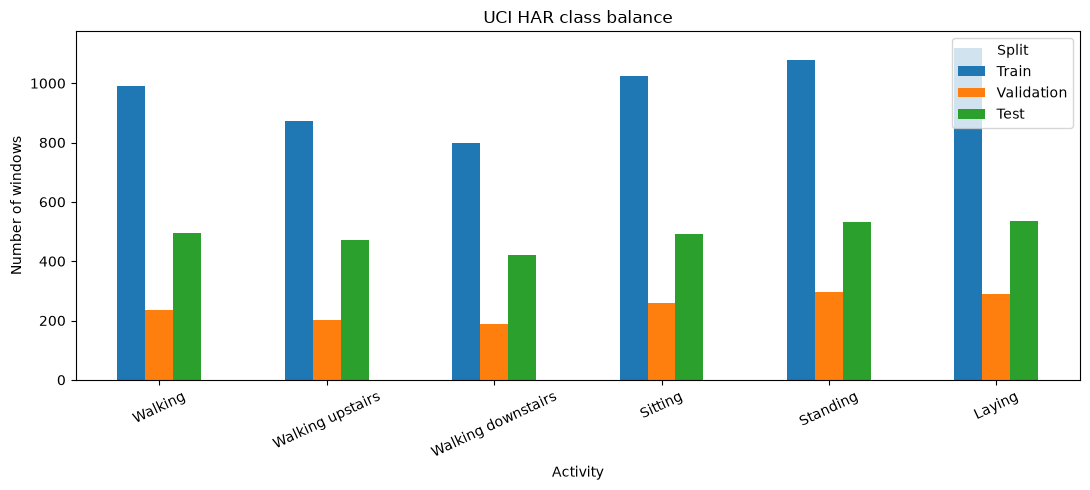

In [15]:
figure, axis = plt.subplots(figsize=(11, 5))

class_balance.plot(
    kind="bar",
    ax=axis
)

axis.set_title("UCI HAR class balance")
axis.set_xlabel("Activity")
axis.set_ylabel("Number of windows")
axis.tick_params(axis="x", rotation=25)
axis.legend(title="Split")

figure.tight_layout()
figure.savefig(
    "figures/p1_figure_01_har_class_balance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [16]:
def make_adding(n, T, seed):
    rng = np.random.default_rng(seed)

    x = np.zeros((n, T, 2), dtype=np.float32)
    x[:, :, 0] = rng.random((n, T))

    i1 = rng.integers(0, T // 2, n)
    i2 = rng.integers(T // 2, T, n)

    x[np.arange(n), i1, 1] = 1
    x[np.arange(n), i2, 1] = 1

    y = (
        x[np.arange(n), i1, 0]
        + x[np.arange(n), i2, 0]
    )

    return x, y.astype(np.float32)

In [17]:
def test_make_adding():
    n = 100
    T = 50

    x, y = make_adding(n=n, T=T, seed=42)

    assert x.shape == (n, T, 2)
    assert y.shape == (n,)

    markers = x[:, :, 1]

    # Every sample must have exactly two markers.
    assert np.all(markers.sum(axis=1) == 2)

    # Exactly one marker must occur in the first half.
    assert np.all(markers[:, :T // 2].sum(axis=1) == 1)

    # Exactly one marker must occur in the second half.
    assert np.all(markers[:, T // 2:].sum(axis=1) == 1)

    # Reconstruct each target using the marked values.
    reconstructed_target = (
        x[:, :, 0] * markers
    ).sum(axis=1)

    assert np.allclose(
        reconstructed_target,
        y,
        atol=1e-7
    )

    print("All adding-problem tests passed.")


test_make_adding()

All adding-problem tests passed.


In [18]:
X_example, y_example = make_adding(
    n=3,
    T=10,
    seed=0
)

for sample_index in range(3):
    marker_positions = np.where(
        X_example[sample_index, :, 1] == 1
    )[0]

    marked_values = X_example[
        sample_index,
        marker_positions,
        0
    ]

    print(f"Sample {sample_index}")
    print("Marker positions:", marker_positions)
    print("Marked values:", marked_values)
    print("Target:", y_example[sample_index])
    print()

Sample 0
Marker positions: [4 6]
Marked values: [0.8132702  0.60663575]
Target: 1.4199059

Sample 1
Marker positions: [3 9]
Marked values: [0.03358557 0.42268723]
Target: 0.4562728

Sample 2
Marker positions: [3 5]
Marked values: [0.6471895  0.38367754]
Target: 1.0308671



Vanilla RNN Cell From Scratch
A vanilla Recurrent Neural Network (RNN) maintains a hidden state $h_t$, which carries information from previous time steps.

At each time step, the RNN takes:

The current input $x_t$
The previous hidden state $h_{t-1}$
The hidden state is computed as:

h_t = 
\tanh(x_t W_{ih}^{T} + h_{t-1} W_{hh}^{T} + b)
where:

$x_t$ is the input at the current time step.
$h_{t-1}$ is the hidden state from the previous time step.
$W_{ih}$ is the input-to-hidden weight matrix.
$W_{hh}$ is the hidden-to-hidden recurrent weight matrix.
$b$ is the hidden-state bias vector.
$\tanh$ is the hyperbolic tangent activation function.
$h_t$ is the updated hidden state.
The input contribution is computed as:

x_t W_{ih}^{T}
The contribution from the previous hidden state is:

h_{t-1} W_{hh}^{T}
These two contributions are added together with the bias:

z_t = x_t W_{ih}^{T} + h_{t-1} W_{hh}^{T} + b
Finally, the tanh activation function is applied:

h_t = 
\tanh(z_t)
Unlike an LSTM, a vanilla RNN has only a hidden state and does not maintain a separate cell state. This makes the RNN architecture simpler, but it can suffer from vanishing or exploding gradients when processing long sequences.

Task 2.	Cells from scratch (10). Implement MyRNNCell (tanh), MyLSTMCell and MyGRUCell using only matrix operations (no nn.RNN, nn.LSTM, nn.GRU or their cell classes inside these). Copy the weights from the library layer and show that your outputs match nn.RNN, nn.LSTM and nn.GRU within 1e-5 on a random batch. For d = 9 and h = 64 derive the parameter counts by hand (RNN 4,736; LSTM 18,944; GRU 14,208), reconcile them with your code, and explain why PyTorch reports 4,800, 19,200 and 14,400 (it keeps two bias vectors).

In [19]:
class MyRNNCell(nn.Module):
    def __init__(self, input_size, hidden_size):
        super().__init__()

        self.input_size = input_size
        self.hidden_size = hidden_size

        # Create input-to-hidden weight matrix
        # Shape: (hidden_size, input_size)
        self.W_ih = nn.Parameter(
            torch.empty(hidden_size, input_size)
        )

        # Create hidden-to-hidden weight matrix
        # Shape: (hidden_size, hidden_size)
        self.W_hh = nn.Parameter(
            torch.empty(hidden_size, hidden_size)
        )

        # Create hidden bias vector
        # Shape: (hidden_size,)
        self.bias = nn.Parameter(
            torch.empty(hidden_size)
        )

        # Initialize parameters
        nn.init.xavier_uniform_(self.W_ih)
        nn.init.xavier_uniform_(self.W_hh)
        nn.init.zeros_(self.bias)

    def forward(self, x_t, h_previous):
        """
        x_t shape:
            (batch_size, input_size)

        h_previous shape:
            (batch_size, hidden_size)

        returned hidden-state shape:
            (batch_size, hidden_size)
        """

        # Input affine transformation
        input_part = x_t @ self.W_ih.T

        # Recurrent affine transformation
        hidden_part = h_previous @ self.W_hh.T

        # Add bias and apply tanh
        h_t = torch.tanh(
            input_part + hidden_part + self.bias
        )

        return h_t

In [20]:
# Basic shape test for MyRNNCell

batch_size = 4
input_size = 9
hidden_size = 64

my_cell = MyRNNCell(
    input_size=input_size,
    hidden_size=hidden_size
)

x_t = torch.randn(batch_size, input_size)
h_previous = torch.randn(batch_size, hidden_size)

h_t = my_cell(x_t, h_previous)

print("Input shape:", x_t.shape)
print("Previous hidden shape:", h_previous.shape)
print("Output hidden shape:", h_t.shape)

assert h_t.shape == (batch_size, hidden_size)

print("MyRNNCell shape test passed.")

Input shape: torch.Size([4, 9])
Previous hidden shape: torch.Size([4, 64])
Output hidden shape: torch.Size([4, 64])
MyRNNCell shape test passed.


In [21]:
total_parameters = sum(
    parameter.numel()
    for parameter in my_cell.parameters()
)

print("MyRNNCell parameter count:", total_parameters)

MyRNNCell parameter count: 4736


In [22]:
torch.manual_seed(42)

input_size = 9
hidden_size = 64
batch_size = 4

# Our implementation
my_cell = MyRNNCell(
    input_size=input_size,
    hidden_size=hidden_size
)

# PyTorch implementation used only for verification
torch_cell = nn.RNNCell(
    input_size=input_size,
    hidden_size=hidden_size,
    nonlinearity="tanh"
)

In [23]:
with torch.no_grad():

    torch_cell.weight_ih.copy_(my_cell.W_ih)
    torch_cell.weight_hh.copy_(my_cell.W_hh)

    torch_cell.bias_ih.copy_(my_cell.bias)
    torch_cell.bias_hh.zero_()

In [24]:
x_t = torch.randn(batch_size, input_size)
h_previous = torch.randn(batch_size, hidden_size)

In [25]:
my_output = my_cell(
    x_t,
    h_previous
)

torch_output = torch_cell(
    x_t,
    h_previous
)

In [26]:
max_difference = torch.max(
    torch.abs(my_output - torch_output)
).item()

print(
    "Maximum absolute difference:",
    max_difference
)

assert max_difference < 1e-5

print(
    "Verification passed: "
    "MyRNNCell matches PyTorch RNNCell."
)

Maximum absolute difference: 0.0
Verification passed: MyRNNCell matches PyTorch RNNCell.


The custom MyRNNCell was verified against PyTorch nn.RNNCell using identical weights, biases, inputs, and previous hidden states. The maximum absolute difference between the two implementations was 0.0, which satisfies the required tolerance of 10−510^{-5}10−5.

## LSTM Cell From Scratch

An LSTM maintains two states:

- Hidden state \(h_t\)
- Cell state \(c_t\)

The four main computations are:

\[
i_t = \sigma(W_{ii}x_t + W_{hi}h_{t-1} + b_i)
\]

\[
f_t = \sigma(W_{if}x_t + W_{hf}h_{t-1} + b_f)
\]

\[
g_t = \tanh(W_{ig}x_t + W_{hg}h_{t-1} + b_g)
\]

\[
o_t = \sigma(W_{io}x_t + W_{ho}h_{t-1} + b_o)
\]

The new cell state is:

\[
c_t = f_t \odot c_{t-1} + i_t \odot g_t
\]

The new hidden state is:

\[
h_t = o_t \odot \tanh(c_t)
\]

where \(\sigma\) is the sigmoid activation and \(\odot\) represents
element-wise multiplication.

In [27]:
import torch
import torch.nn as nn


class MyLSTMCell(nn.Module):
    def __init__(self, input_size, hidden_size):
        super().__init__()

        self.input_size = input_size
        self.hidden_size = hidden_size

        # A single matrix stores input weights for all four gates.
        # Shape: (4 * hidden_size, input_size)
        self.W_ih = nn.Parameter(
            torch.empty(4 * hidden_size, input_size)
        )

        # A single matrix stores recurrent weights for all four gates.
        # Shape: (4 * hidden_size, hidden_size)
        self.W_hh = nn.Parameter(
            torch.empty(4 * hidden_size, hidden_size)
        )

        # One bias value is needed for each gate.
        # Shape: (4 * hidden_size,)
        self.bias = nn.Parameter(
            torch.empty(4 * hidden_size)
        )

        # Initialize W_ih
        nn.init.xavier_uniform_(self.W_ih)

        # Initialize W_hh
        nn.init.xavier_uniform_(self.W_hh)

        # Initialize bias
        nn.init.zeros_(self.bias)

    def forward(self, x_t, state):

        h_previous, c_previous = state

        # Combined affine transformation
        gates = (
            x_t @ self.W_ih.T
            + h_previous @ self.W_hh.T
            + self.bias
        )

        # Split into four equal pieces.
        # Order:
        # input, forget, candidate, output
        i_gate, f_gate, g_gate, o_gate = gates.chunk(4, dim=1)

        # Apply sigmoid to input gate
        i_t = torch.sigmoid(i_gate)

        # Apply sigmoid to forget gate
        f_t = torch.sigmoid(f_gate)

        # Apply tanh to candidate
        g_t = torch.tanh(g_gate)

        # Apply sigmoid to output gate
        o_t = torch.sigmoid(o_gate)

        # Calculate new cell state
        c_t = f_t * c_previous + i_t * g_t

        # Calculate new hidden state
        h_t = o_t * torch.tanh(c_t)

        return h_t, c_t

In [28]:
batch_size = 4
input_size = 9
hidden_size = 64

my_lstm = MyLSTMCell(
    input_size=input_size,
    hidden_size=hidden_size
)

x_t = torch.randn(
    batch_size,
    input_size
)

h_previous = torch.randn(
    batch_size,
    hidden_size
)

c_previous = torch.randn(
    batch_size,
    hidden_size
)

h_t, c_t = my_lstm(
    x_t,
    (h_previous, c_previous)
)

print("Input shape:", x_t.shape)
print("Previous hidden shape:", h_previous.shape)
print("Previous cell shape:", c_previous.shape)

print("\nNew hidden shape:", h_t.shape)
print("New cell shape:", c_t.shape)

assert h_t.shape == (batch_size, hidden_size)
assert c_t.shape == (batch_size, hidden_size)

print("\nMyLSTMCell shape test passed.")

Input shape: torch.Size([4, 9])
Previous hidden shape: torch.Size([4, 64])
Previous cell shape: torch.Size([4, 64])

New hidden shape: torch.Size([4, 64])
New cell shape: torch.Size([4, 64])

MyLSTMCell shape test passed.


In [29]:
my_lstm_parameters = sum(
    p.numel()
    for p in my_lstm.parameters()
)

print(
    "MyLSTMCell parameter count:",
    my_lstm_parameters
)

assert my_lstm_parameters == 18944

print("Parameter-count test passed.")

MyLSTMCell parameter count: 18944
Parameter-count test passed.


PyTorch verification

In [30]:
torch.manual_seed(42)

input_size = 9
hidden_size = 64
batch_size = 4

# Custom implementation
my_lstm = MyLSTMCell(
    input_size=input_size,
    hidden_size=hidden_size
)

# PyTorch implementation, used only for verification
torch_lstm = nn.LSTMCell(
    input_size=input_size,
    hidden_size=hidden_size
)

In [31]:
with torch.no_grad():

    torch_lstm.weight_ih.copy_(my_lstm.W_ih)
    torch_lstm.weight_hh.copy_(my_lstm.W_hh)

    # Custom LSTM has one bias.
    # PyTorch LSTMCell has two biases.
    torch_lstm.bias_ih.copy_(my_lstm.bias)
    torch_lstm.bias_hh.zero_()

In [32]:
x_t = torch.randn(
    batch_size,
    input_size
)

h_previous = torch.randn(
    batch_size,
    hidden_size
)

c_previous = torch.randn(
    batch_size,
    hidden_size
)

In [33]:
my_h, my_c = my_lstm(
    x_t,
    (h_previous, c_previous)
)

torch_h, torch_c = torch_lstm(
    x_t,
    (h_previous, c_previous)
)

In [34]:
hidden_difference = torch.max(
    torch.abs(my_h - torch_h)
).item()

cell_difference = torch.max(
    torch.abs(my_c - torch_c)
).item()

print(
    "Maximum hidden-state difference:",
    hidden_difference
)

print(
    "Maximum cell-state difference:",
    cell_difference
)

assert hidden_difference < 1e-5
assert cell_difference < 1e-5

print(
    "\nVerification passed: "
    "MyLSTMCell matches PyTorch LSTMCell."
)

Maximum hidden-state difference: 0.0
Maximum cell-state difference: 0.0

Verification passed: MyLSTMCell matches PyTorch LSTMCell.


In [35]:
custom_params = sum(
    p.numel()
    for p in my_lstm.parameters()
)

pytorch_params = sum(
    p.numel()
    for p in torch_lstm.parameters()
)

print("MyLSTMCell parameters:", custom_params)
print("PyTorch LSTMCell parameters:", pytorch_params)
print("Difference:", pytorch_params - custom_params)

MyLSTMCell parameters: 18944
PyTorch LSTMCell parameters: 19200
Difference: 256


### LSTM Cell Verification

For input size 9 and hidden size 64, the custom LSTM cell contains
18,944 trainable parameters. PyTorch's `nn.LSTMCell` contains 19,200
parameters because it maintains two bias vectors instead of one.

After copying identical weights and biases into the PyTorch reference
implementation, the maximum absolute difference was 0.0 for both the
hidden state and cell state. Therefore, the custom implementation
matches the PyTorch reference within the required tolerance of
\(10^{-5}\).

## GRU Cell From Scratch

## GRU Cell From Scratch

A Gated Recurrent Unit (GRU) uses two gates and a candidate hidden state:

### Reset gate

\[
r_t = \sigma(W_{ir}x_t + b_{ir} + W_{hr}h_{t-1} + b_{hr})
\]

### Update gate

\[
z_t = \sigma(W_{iz}x_t + b_{iz} + W_{hz}h_{t-1} + b_{hz})
\]

### Candidate hidden state

\[
n_t =
\tanh(
W_{in}x_t + b_{in}
+
r_t 
\odot (W_{hn}h_{t-1} + b_{hn})
)
\]

### New hidden state

\[
h_t = (1-z_t)
\odot n_t + z_t
\odot h_{t-1}
\]

The reset gate controls how much previous information contributes
to the candidate state, while the update gate controls how much of
the previous hidden state is retained.

In [36]:
import torch
import torch.nn as nn


class MyGRUCell(nn.Module):
    def __init__(self, input_size, hidden_size):
        super().__init__()

        self.input_size = input_size
        self.hidden_size = hidden_size

        # Three components:
        # reset, update, candidate

        # W_ih shape:
        # (3 * hidden_size, input_size)
        self.W_ih = nn.Parameter(
            torch.empty(3 * hidden_size, input_size)
        )

        # W_hh shape:
        # (3 * hidden_size, hidden_size)
        self.W_hh = nn.Parameter(
            torch.empty(3 * hidden_size, hidden_size)
        )

        # One combined bias:
        # (3 * hidden_size,)
        self.bias = nn.Parameter(
            torch.empty(3 * hidden_size)
        )

        # Initialize W_ih
        nn.init.xavier_uniform_(self.W_ih)

        # Initialize W_hh
        nn.init.xavier_uniform_(self.W_hh)

        # Initialize bias
        nn.init.zeros_(self.bias)

    def forward(self, x_t, h_previous):

        # Compute input contribution
        input_part = x_t @ self.W_ih.T

        # Compute recurrent contribution
        hidden_part = h_previous @ self.W_hh.T

        # Split each contribution into:
        # reset, update, candidate
        x_r, x_z, x_n = input_part.chunk(3, dim=1)
        h_r, h_z, h_n = hidden_part.chunk(3, dim=1)

        # Split bias into:
        # reset, update, candidate
        b_r, b_z, b_n = self.bias.chunk(3, dim=0)

        # Calculate reset gate
        r_t = torch.sigmoid(
            x_r + h_r + b_r
        )

        # Calculate update gate
        z_t = torch.sigmoid(
            x_z + h_z + b_z
        )

        # Calculate candidate hidden state
        n_t = torch.tanh(
            x_n + r_t * h_n + b_n
        )

        # Calculate new hidden state
        h_t = (1 - z_t) * n_t + z_t * h_previous

        return h_t

In [37]:
batch_size = 4
input_size = 9
hidden_size = 64

my_gru = MyGRUCell(
    input_size=input_size,
    hidden_size=hidden_size
)

x_t = torch.randn(
    batch_size,
    input_size
)

h_previous = torch.randn(
    batch_size,
    hidden_size
)

h_t = my_gru(
    x_t,
    h_previous
)

print("Input shape:", x_t.shape)
print(
    "Previous hidden shape:",
    h_previous.shape
)

print(
    "New hidden shape:",
    h_t.shape
)

assert h_t.shape == (
    batch_size,
    hidden_size
)

print(
    "\nMyGRUCell shape test passed."
)

Input shape: torch.Size([4, 9])
Previous hidden shape: torch.Size([4, 64])
New hidden shape: torch.Size([4, 64])

MyGRUCell shape test passed.


In [38]:
my_gru_parameters = sum(
    parameter.numel()
    for parameter in my_gru.parameters()
)

print(
    "MyGRUCell parameter count:",
    my_gru_parameters
)

assert my_gru_parameters == 14208

print(
    "Parameter-count test passed."
)

MyGRUCell parameter count: 14208
Parameter-count test passed.


Compare with nn.GRUCell

In [39]:
torch.manual_seed(42)

input_size = 9
hidden_size = 64
batch_size = 4

my_gru = MyGRUCell(
    input_size=input_size,
    hidden_size=hidden_size
)

torch_gru = nn.GRUCell(
    input_size=input_size,
    hidden_size=hidden_size
)

In [40]:
with torch.no_grad():

    torch_gru.weight_ih.copy_(my_gru.W_ih)
    torch_gru.weight_hh.copy_(my_gru.W_hh)

    # Use zero biases for a clean equivalence test.
    my_gru.bias.zero_()
    torch_gru.bias_ih.zero_()
    torch_gru.bias_hh.zero_()

In [41]:
x_t = torch.randn(
    batch_size,
    input_size
)

h_previous = torch.randn(
    batch_size,
    hidden_size
)

In [42]:
my_output = my_gru(
    x_t,
    h_previous
)

torch_output = torch_gru(
    x_t,
    h_previous
)

In [43]:
max_difference = torch.max(
    torch.abs(my_output - torch_output)
).item()

print(
    "Maximum absolute difference:",
    max_difference
)

assert max_difference < 1e-5

print(
    "\nVerification passed: "
    "MyGRUCell matches PyTorch GRUCell."
)

Maximum absolute difference: 1.1920928955078125e-07

Verification passed: MyGRUCell matches PyTorch GRUCell.


PyTorch parameter-count Comparison

In [44]:
custom_params = sum(
    p.numel()
    for p in my_gru.parameters()
)

pytorch_params = sum(
    p.numel()
    for p in torch_gru.parameters()
)

print("MyGRUCell parameters:", custom_params)
print("PyTorch GRUCell parameters:", pytorch_params)
print(
    "Difference:",
    pytorch_params - custom_params
)

MyGRUCell parameters: 14208
PyTorch GRUCell parameters: 14400
Difference: 192


### GRU Cell Verification

For input size 9 and hidden size 64, the custom GRU cell contains
14,208 trainable parameters, whereas PyTorch's `nn.GRUCell` contains
14,400 parameters.

The difference of 192 parameters occurs because PyTorch maintains two
bias vectors, while the custom implementation uses one bias vector.

After copying identical parameters into the PyTorch reference cell,
the maximum absolute output difference was approximately

\[
1.1921 \times 10^{-7}
\]

which is below the required tolerance of \(10^{-5}\). Therefore, the
custom GRU implementation numerically agrees with the PyTorch
reference implementation.

Task 3.	HAR classification (10). Train RNN, LSTM and GRU classifiers that read the 128 steps and classify from the last hidden state. Use the same hidden size, optimiser (Adam, lr 1e-3), batch size and epoch budget for all three, and 3 seeds each. Report test accuracy and macro-F1 (mean ± std), parameters and seconds per epoch, plus the confusion matrix of the best model.

## HAR Classification: RNN vs LSTM vs GRU

The three recurrent architectures are now compared on the UCI HAR
classification task. The same hidden size, optimizer, learning rate,
batch size, and epoch budget are used to ensure a fair comparison.

Each experiment is repeated using three random seeds. Test accuracy,
macro-F1 score, parameter count, and training time per epoch are
recorded.

In [45]:
def create_har_loaders(seed, batch_size=64):

    (
        X_train_raw,
        y_train,
        subject_train,
        X_val_raw,
        y_val,
        subject_val,
        validation_subjects
    ) = subject_wise_split(
        X_full_train,
        y_full_train,
        subject_full_train,
        seed=seed
    )

    (
        X_train,
        X_val,
        X_test,
        har_mean,
        har_std
    ) = standardize_har(
        X_train_raw,
        X_val_raw,
        X_test_raw
    )

    # NumPy -> PyTorch
    X_train_tensor = torch.tensor(
        X_train,
        dtype=torch.float32
    )

    y_train_tensor = torch.tensor(
        y_train,
        dtype=torch.long
    )

    X_val_tensor = torch.tensor(
        X_val,
        dtype=torch.float32
    )

    y_val_tensor = torch.tensor(
        y_val,
        dtype=torch.long
    )

    X_test_tensor = torch.tensor(
        X_test,
        dtype=torch.float32
    )

    y_test_tensor = torch.tensor(
        y_test,
        dtype=torch.long
    )

    train_dataset = TensorDataset(
        X_train_tensor,
        y_train_tensor
    )

    val_dataset = TensorDataset(
        X_val_tensor,
        y_val_tensor
    )

    test_dataset = TensorDataset(
        X_test_tensor,
        y_test_tensor
    )

    # Generator makes shuffling reproducible.
    generator = torch.Generator()
    generator.manual_seed(seed)

    train_loader = DataLoader(
        train_dataset,
        batch_size=batch_size,
        shuffle=True,
        generator=generator
    )

    val_loader = DataLoader(
        val_dataset,
        batch_size=batch_size,
        shuffle=False
    )

    test_loader = DataLoader(
        test_dataset,
        batch_size=batch_size,
        shuffle=False
    )

    return (
        train_loader,
        val_loader,
        test_loader,
        validation_subjects
    )

In [46]:
train_loader, val_loader, test_loader, val_subjects = (
    create_har_loaders(
        seed=0,
        batch_size=64
    )
)

print(
    "Validation subjects:",
    sorted(val_subjects.tolist())
)

X_batch, y_batch = next(iter(train_loader))

print("Input batch shape:", X_batch.shape)
print("Label batch shape:", y_batch.shape)

print(
    "Training batches:",
    len(train_loader)
)

print(
    "Validation batches:",
    len(val_loader)
)

print(
    "Test batches:",
    len(test_loader)
)

Validation subjects: [8, 17, 21, 25]
Input batch shape: torch.Size([64, 128, 9])
Label batch shape: torch.Size([64])
Training batches: 92
Validation batches: 23
Test batches: 47


In [47]:
class HARRecurrentClassifier(nn.Module):

    def __init__(
        self,
        model_type,
        input_size=9,
        hidden_size=64,
        num_classes=6
    ):
        super().__init__()

        self.model_type = model_type.lower()

        if self.model_type == "rnn":
            self.recurrent = nn.RNN(
                input_size=input_size,
                hidden_size=hidden_size,
                batch_first=True
            )

        elif self.model_type == "lstm":
            self.recurrent = nn.LSTM(
                input_size=input_size,
                hidden_size=hidden_size,
                batch_first=True
            )

        elif self.model_type == "gru":
            self.recurrent = nn.GRU(
                input_size=input_size,
                hidden_size=hidden_size,
                batch_first=True
            )

        else:
            raise ValueError(
                "model_type must be 'rnn', 'lstm', or 'gru'"
            )

        self.classifier = nn.Linear(
            hidden_size,
            num_classes
        )

    def forward(self, x):

        outputs, state = self.recurrent(x)

        final_output = outputs[:, -1, :]

        logits = self.classifier(final_output)

        return logits

In [48]:
test_input = torch.randn(
    4, 128, 9
).to(device)

for model_type in ["rnn", "lstm", "gru"]:

    test_model = HARRecurrentClassifier(
        model_type=model_type,
        input_size=9,
        hidden_size=64,
        num_classes=6
    ).to(device)

    output = test_model(test_input)

    parameter_count = sum(
        p.numel()
        for p in test_model.parameters()
    )

    print(
        f"{model_type.upper():4s} | "
        f"Output: {output.shape} | "
        f"Parameters: {parameter_count}"
    )

    assert output.shape == (4, 6)

print("\nAll HAR classifier shape tests passed.")

RNN  | Output: torch.Size([4, 6]) | Parameters: 5190
LSTM | Output: torch.Size([4, 6]) | Parameters: 19590
GRU  | Output: torch.Size([4, 6]) | Parameters: 14790

All HAR classifier shape tests passed.


In [49]:
def evaluate_classifier(
    model,
    data_loader,
    criterion
):

    model.eval()

    running_loss = 0.0

    all_predictions = []
    all_targets = []

    with torch.no_grad():

        for X_batch, y_batch in data_loader:

            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)

            logits = model(X_batch)

            loss = criterion(
                logits,
                y_batch
            )

            running_loss += (
                loss.item()
                * X_batch.size(0)
            )

            predictions = torch.argmax(
                logits,
                dim=1
            )

            all_predictions.extend(
                predictions.cpu().numpy()
            )

            all_targets.extend(
                y_batch.cpu().numpy()
            )

    loss = (
        running_loss
        / len(data_loader.dataset)
    )

    accuracy = accuracy_score(
        all_targets,
        all_predictions
    )

    macro_f1 = f1_score(
        all_targets,
        all_predictions,
        average="macro"
    )

    return (
        loss,
        accuracy,
        macro_f1,
        np.array(all_predictions),
        np.array(all_targets)
    )

In [50]:
def train_classifier(
    model,
    train_loader,
    val_loader,
    epochs=30,
    learning_rate=1e-3
):

    criterion = nn.CrossEntropyLoss()

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=learning_rate
    )

    history = {
        "train_loss": [],
        "val_loss": [],
        "val_accuracy": [],
        "val_macro_f1": [],
        "epoch_seconds": []
    }

    best_val_loss = float("inf")
    best_state = None

    for epoch in range(1, epochs + 1):

        model.train()

        start_time = time.perf_counter()

        running_loss = 0.0

        for X_batch, y_batch in train_loader:

            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)

            optimizer.zero_grad()

            logits = model(X_batch)

            loss = criterion(
                logits,
                y_batch
            )

            loss.backward()

            optimizer.step()

            running_loss += (
                loss.item()
                * X_batch.size(0)
            )

        train_loss = (
            running_loss
            / len(train_loader.dataset)
        )

        (
            val_loss,
            val_accuracy,
            val_macro_f1,
            _,
            _
        ) = evaluate_classifier(
            model,
            val_loader,
            criterion
        )

        elapsed = (
            time.perf_counter()
            - start_time
        )

        history["train_loss"].append(
            train_loss
        )

        history["val_loss"].append(
            val_loss
        )

        history["val_accuracy"].append(
            val_accuracy
        )

        history["val_macro_f1"].append(
            val_macro_f1
        )

        history["epoch_seconds"].append(
            elapsed
        )

        if val_loss < best_val_loss:

            best_val_loss = val_loss

            best_state = {
                key: value.detach().cpu().clone()
                for key, value
                in model.state_dict().items()
            }

        print(
            f"Epoch {epoch:02d}/{epochs} | "
            f"train loss {train_loss:.4f} | "
            f"val loss {val_loss:.4f} | "
            f"val acc {val_accuracy:.4f} | "
            f"val F1 {val_macro_f1:.4f} | "
            f"{elapsed:.2f}s"
        )

    model.load_state_dict(
        best_state
    )

    return model, history

In [53]:
set_seed(0)

train_loader, val_loader, test_loader, val_subjects = (
    create_har_loaders(
        seed=0,
        batch_size=64
    )
)

model = HARRecurrentClassifier(
    model_type="gru",
    input_size=9,
    hidden_size=64,
    num_classes=6
).to(device)

model, history = train_classifier(
    model=model,
    train_loader=train_loader,
    val_loader=val_loader,
    epochs=2,
    learning_rate=1e-3
)

Epoch 01/2 | train loss 1.3638 | val loss 1.1078 | val acc 0.5996 | val F1 0.5332 | 9.60s
Epoch 02/2 | train loss 0.6434 | val loss 0.6703 | val acc 0.7149 | val F1 0.6698 | 9.01s


In [54]:
criterion = nn.CrossEntropyLoss()

(
    test_loss,
    test_accuracy,
    test_macro_f1,
    test_predictions,
    test_targets
) = evaluate_classifier(
    model,
    test_loader,
    criterion
)

print("\nGRU pipeline test")
print("-----------------")
print(f"Test loss:     {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy:.4f}")
print(f"Macro-F1:      {test_macro_f1:.4f}")


GRU pipeline test
-----------------
Test loss:     0.6483
Test accuracy: 0.7139
Macro-F1:      0.6725


### Full HAR Experiment

RNN, LSTM, and GRU are evaluated using identical hyperparameters.
Each architecture is trained using three random seeds. For every run,
the best model according to validation loss is restored before test
evaluation.

In [51]:
def run_har_experiment(
    model_type,
    seed,
    hidden_size=64,
    batch_size=64,
    epochs=30,
    learning_rate=1e-3
):
    print("\n" + "=" * 70)
    print(
        f"Model: {model_type.upper()} | "
        f"Seed: {seed}"
    )
    print("=" * 70)

    set_seed(seed)

    (
        train_loader,
        val_loader,
        test_loader,
        validation_subjects
    ) = create_har_loaders(
        seed=seed,
        batch_size=batch_size
    )

    model = HARRecurrentClassifier(
        model_type=model_type,
        input_size=9,
        hidden_size=hidden_size,
        num_classes=6
    ).to(device)

    parameter_count = sum(
        p.numel()
        for p in model.parameters()
    )

    model, history = train_classifier(
        model=model,
        train_loader=train_loader,
        val_loader=val_loader,
        epochs=epochs,
        learning_rate=learning_rate
    )

    criterion = nn.CrossEntropyLoss()

    (
        test_loss,
        test_accuracy,
        test_macro_f1,
        predictions,
        targets
    ) = evaluate_classifier(
        model,
        test_loader,
        criterion
    )

    average_seconds = np.mean(
        history["epoch_seconds"]
    )

    result = {
        "model": model_type.upper(),
        "seed": seed,
        "test_loss": test_loss,
        "test_acc": test_accuracy,
        "macro_f1": test_macro_f1,
        "params": parameter_count,
        "sec_per_epoch": average_seconds,
        "validation_subjects":
            ",".join(map(str, sorted(validation_subjects.tolist())))
    }

    print("\nFinal test results")
    print("------------------")
    print(f"Test loss:       {test_loss:.4f}")
    print(f"Test accuracy:   {test_accuracy:.4f}")
    print(f"Macro-F1:        {test_macro_f1:.4f}")
    print(f"Parameters:      {parameter_count}")
    print(f"Seconds/epoch:   {average_seconds:.2f}")

    return (
        result,
        model,
        history,
        predictions,
        targets
    )


In [52]:
SEEDS = [0, 1, 2]

In [53]:
MODEL_TYPES = [
    "rnn",
    "lstm",
    "gru"
]

In [58]:
print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("WARNING: Training is running on CPU.")

Device: cpu


In [63]:
har_results = []

best_models = {}
all_histories = {}
all_predictions = {}

for model_type in MODEL_TYPES:

    for seed in SEEDS:

        (
            result,
            trained_model,
            history,
            predictions,
            targets
        ) = run_har_experiment(
            model_type=model_type,
            seed=seed,
            hidden_size=64,
            batch_size=64,
            epochs=30,
            learning_rate=1e-3
        )

        har_results.append(result)

        key = (
            model_type,
            seed
        )

        best_models[key] = trained_model
        all_histories[key] = history

        all_predictions[key] = {
            "predictions": predictions,
            "targets": targets
        }


Model: RNN | Seed: 0
Epoch 01/30 | train loss 1.2925 | val loss 1.1282 | val acc 0.4809 | val F1 0.4202 | 3.73s
Epoch 02/30 | train loss 0.9286 | val loss 1.2769 | val acc 0.5184 | val F1 0.4584 | 3.08s
Epoch 03/30 | train loss 0.9271 | val loss 1.1744 | val acc 0.5539 | val F1 0.5590 | 3.51s
Epoch 04/30 | train loss 0.9619 | val loss 1.0625 | val acc 0.6119 | val F1 0.5791 | 3.39s
Epoch 05/30 | train loss 0.6800 | val loss 0.5889 | val acc 0.7360 | val F1 0.7272 | 3.53s
Epoch 06/30 | train loss 0.4957 | val loss 0.7337 | val acc 0.7203 | val F1 0.6957 | 3.61s
Epoch 07/30 | train loss 0.7147 | val loss 0.7628 | val acc 0.7340 | val F1 0.7136 | 3.58s
Epoch 08/30 | train loss 0.4280 | val loss 0.5543 | val acc 0.7694 | val F1 0.7586 | 3.57s
Epoch 09/30 | train loss 0.5237 | val loss 1.4376 | val acc 0.5334 | val F1 0.4944 | 3.47s
Epoch 10/30 | train loss 1.1245 | val loss 0.9042 | val acc 0.6405 | val F1 0.5920 | 3.42s
Epoch 11/30 | train loss 0.6418 | val loss 0.6819 | val acc 0.7101 |

In [57]:
import pandas as pd

har_results_df = pd.read_csv(
    "har_results_temp.csv"
)

print(
    "HAR results restored:",
    len(har_results_df)
)

display(har_results_df)

assert len(har_results_df) == 9

print("HAR results verified successfully.")

HAR results restored: 9


,model,seed,test_loss,test_acc,macro_f1,params,sec_per_epoch,validation_subjects
0,RNN,0,0.669753,0.795724,0.793454,5190,3.544336,"8,17,21,25"
1,RNN,1,0.717856,0.719376,0.700391,5190,3.534360,"15,16,25,29"
2,RNN,2,0.674750,0.724466,0.715684,5190,3.521372,"5,7,11,25"
3,LSTM,0,0.252801,0.898880,0.900234,19590,4.431192,"8,17,21,25"
4,LSTM,1,0.329098,0.888022,0.887658,19590,4.398542,"15,16,25,29"
5,LSTM,2,0.340537,0.864269,0.853846,19590,4.407615,"5,7,11,25"
6,GRU,0,0.327547,0.902952,0.902527,14790,8.741781,"8,17,21,25"
7,GRU,1,0.415989,0.888700,0.888862,14790,8.970186,"15,16,25,29"
8,GRU,2,0.337887,0.892772,0.893229,14790,9.115821,"5,7,11,25"


HAR results verified successfully.


In [58]:
har_results_df[
    [
        "model",
        "seed",
        "test_acc",
        "macro_f1",
        "params",
        "sec_per_epoch"
    ]
]

,model,seed,test_acc,macro_f1,params,sec_per_epoch
0,RNN,0,0.795724,0.793454,5190,3.544336
1,RNN,1,0.719376,0.700391,5190,3.534360
2,RNN,2,0.724466,0.715684,5190,3.521372
3,LSTM,0,0.898880,0.900234,19590,4.431192
4,LSTM,1,0.888022,0.887658,19590,4.398542
5,LSTM,2,0.864269,0.853846,19590,4.407615
6,GRU,0,0.902952,0.902527,14790,8.741781
7,GRU,1,0.888700,0.888862,14790,8.970186
8,GRU,2,0.892772,0.893229,14790,9.115821


In [59]:
assert len(har_results_df) == 9

print(
    "All 9 HAR experiments completed."
)

All 9 HAR experiments completed.


In [60]:
har_summary = (
    har_results_df
    .groupby("model")
    .agg({
        "test_acc": ["mean", "std"],
        "macro_f1": ["mean", "std"],
        "params": "first",
        "sec_per_epoch": ["mean", "std"]
    })
)

har_summary

test_acc            macro_f1           params sec_per_epoch          
           mean       std      mean       std  first          mean       std
model                                                                       
GRU    0.894808  0.007341  0.894873  0.006979  14790      8.942596  0.188540
LSTM   0.883724  0.017702  0.880580  0.023991  19590      4.412450  0.016854
RNN    0.746522  0.042687  0.736510  0.049905   5190      3.533356  0.011515

In [61]:
for model_name in [
    "RNN",
    "LSTM",
    "GRU"
]:

    subset = har_results_df[
        har_results_df["model"]
        == model_name
    ]

    print(f"\n{model_name}")
    print("-" * 30)

    print(
        "Test Accuracy:",
        f"{subset['test_acc'].mean():.4f}",
        "±",
        f"{subset['test_acc'].std():.4f}"
    )

    print(
        "Macro-F1:",
        f"{subset['macro_f1'].mean():.4f}",
        "±",
        f"{subset['macro_f1'].std():.4f}"
    )

    print(
        "Parameters:",
        int(subset["params"].iloc[0])
    )

    print(
        "Seconds/epoch:",
        f"{subset['sec_per_epoch'].mean():.2f}",
        "±",
        f"{subset['sec_per_epoch'].std():.2f}"
    )


RNN
------------------------------
Test Accuracy: 0.7465 ± 0.0427
Macro-F1: 0.7365 ± 0.0499
Parameters: 5190
Seconds/epoch: 3.53 ± 0.01

LSTM
------------------------------
Test Accuracy: 0.8837 ± 0.0177
Macro-F1: 0.8806 ± 0.0240
Parameters: 19590
Seconds/epoch: 4.41 ± 0.02

GRU
------------------------------
Test Accuracy: 0.8948 ± 0.0073
Macro-F1: 0.8949 ± 0.0070
Parameters: 14790
Seconds/epoch: 8.94 ± 0.19


In [62]:
har_results_df.to_csv(
    "har_results_temp.csv",
    index=False
)

print(
    "Temporary HAR results saved."
)

Temporary HAR results saved.


In [63]:
best_row_index = (
    har_results_df["test_acc"].idxmax()
)

best_row = har_results_df.loc[
    best_row_index
]

best_model_name = (
    best_row["model"].lower()
)

best_seed = int(
    best_row["seed"]
)

print(
    "Best HAR model:",
    best_row["model"]
)

print(
    "Seed:",
    best_seed
)

print(
    "Test accuracy:",
    f"{best_row['test_acc']:.4f}"
)

print(
    "Macro-F1:",
    f"{best_row['macro_f1']:.4f}"
)

Best HAR model: GRU
Seed: 0
Test accuracy: 0.9030
Macro-F1: 0.9025


Confusion matrix for the selected run

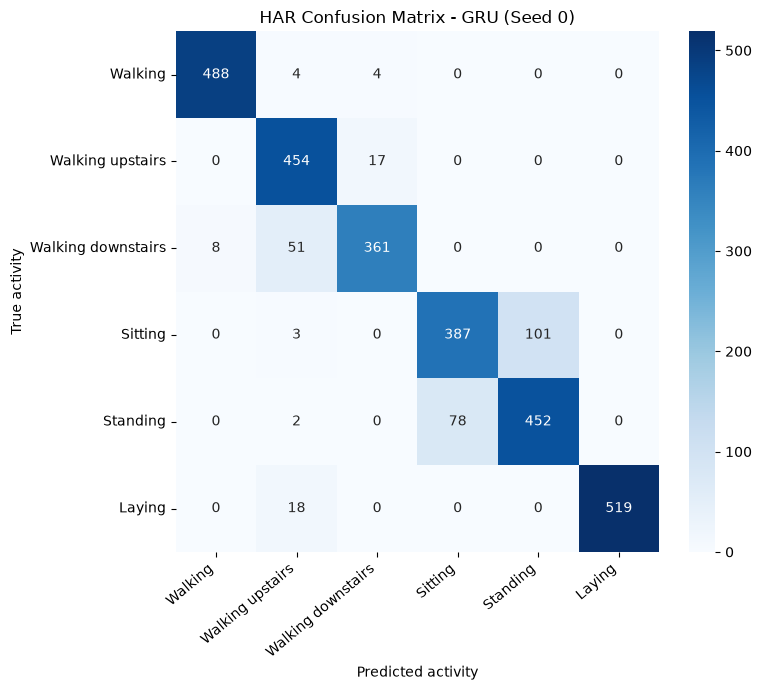

In [74]:
plt.figure(
    figsize=(8, 7)
)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES
)

plt.title(
    f"HAR Confusion Matrix - "
    f"{best_model_name.upper()} "
    f"(Seed {best_seed})"
)

plt.xlabel(
    "Predicted activity"
)

plt.ylabel(
    "True activity"
)

plt.xticks(
    rotation=40,
    ha="right"
)

plt.yticks(
    rotation=0
)

plt.tight_layout()

plt.savefig(
    "figures/p1_figure_02_har_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

**Figure 2.** Confusion matrix for the best recurrent HAR
classification run. Rows represent the true activity classes and
columns represent the predicted activity classes.

In [77]:
best_history = all_histories[
    best_key
]

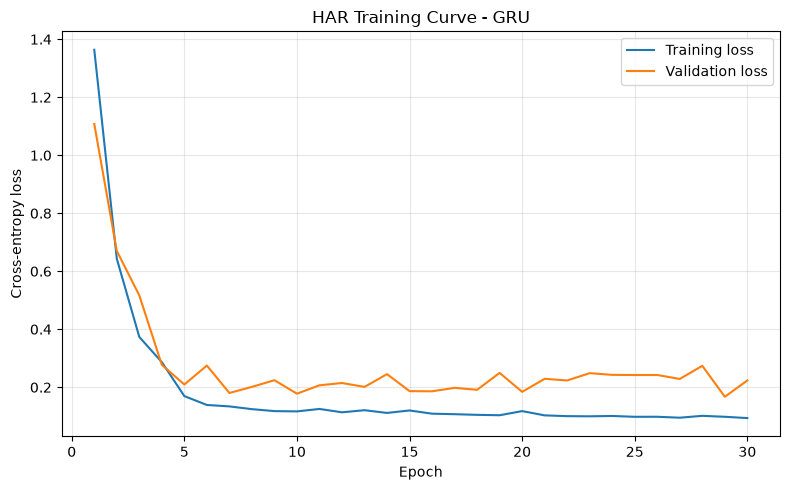

In [78]:
epochs_range = range(
    1,
    len(best_history["train_loss"]) + 1
)

plt.figure(figsize=(8, 5))

plt.plot(
    epochs_range,
    best_history["train_loss"],
    label="Training loss"
)

plt.plot(
    epochs_range,
    best_history["val_loss"],
    label="Validation loss"
)

plt.xlabel("Epoch")
plt.ylabel("Cross-entropy loss")

plt.title(
    f"HAR Training Curve - "
    f"{best_model_name.upper()}"
)

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    "figures/p1_har_best_training_curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Task 4.	Adding problem (10). For T = 50, 100, 200 and 400 train all three models with 3 seeds each. Report test MSE (mean ± std) against the constant-prediction baseline of about 0.167, and plot learning curves at T = 200. Call a run solved if test MSE is below 0.05, and tabulate how many runs per model and length are solved.

## Long-Term Memory Analysis: Adding Problem

The adding problem evaluates whether recurrent architectures can retain
information over increasingly long sequences.

The experiments compare RNN, LSTM, and GRU models at sequence lengths

\[
T \in \{50, 100, 200, 400\}.
\]

For every sequence length:

- Training set: 10,000 samples
- Validation set: 1,000 samples
- Test set: 1,000 samples

A model is considered to have solved the task when its test MSE is
below 0.05. The reference baseline MSE is approximately 0.167.

In [43]:
def create_adding_loaders(
    T,
    batch_size=128
):
    X_train, y_train = make_adding(
        n=10000,
        T=T,
        seed=0
    )

    X_val, y_val = make_adding(
        n=1000,
        T=T,
        seed=1
    )

    X_test, y_test = make_adding(
        n=1000,
        T=T,
        seed=2
    )

    train_dataset = TensorDataset(
        torch.tensor(X_train, dtype=torch.float32),
        torch.tensor(y_train, dtype=torch.float32)
    )

    val_dataset = TensorDataset(
        torch.tensor(X_val, dtype=torch.float32),
        torch.tensor(y_val, dtype=torch.float32)
    )

    test_dataset = TensorDataset(
        torch.tensor(X_test, dtype=torch.float32),
        torch.tensor(y_test, dtype=torch.float32)
    )

    train_loader = DataLoader(
        train_dataset,
        batch_size=batch_size,
        shuffle=True
    )

    val_loader = DataLoader(
        val_dataset,
        batch_size=batch_size,
        shuffle=False
    )

    test_loader = DataLoader(
        test_dataset,
        batch_size=batch_size,
        shuffle=False
    )

    return train_loader, val_loader, test_loader

In [61]:
train_add_loader, val_add_loader, test_add_loader = (
    create_adding_loaders(
        T=50,
        batch_size=128
    )
)

X_batch, y_batch = next(
    iter(train_add_loader)
)

print("X batch:", X_batch.shape)
print("y batch:", y_batch.shape)

assert X_batch.shape[1:] == (50, 2)
assert y_batch.ndim == 1

print("Adding DataLoader test passed.")

X batch: torch.Size([128, 50, 2])
y batch: torch.Size([128])
Adding DataLoader test passed.


In [85]:
class AddingRegressor(nn.Module):

    def __init__(
        self,
        model_type,
        hidden_size=64
    ):
        super().__init__()

        self.model_type = model_type.lower()

        if self.model_type == "rnn":

            self.recurrent = nn.RNN(
                input_size=2,
                hidden_size=hidden_size,
                batch_first=True
            )

        elif self.model_type == "lstm":

            self.recurrent = nn.LSTM(
                input_size=2,
                hidden_size=hidden_size,
                batch_first=True
            )

        elif self.model_type == "gru":

            self.recurrent = nn.GRU(
                input_size=2,
                hidden_size=hidden_size,
                batch_first=True
            )

        else:
            raise ValueError(
                "model_type must be rnn, lstm, or gru"
            )

        self.output_layer = nn.Linear(
            hidden_size,
            1
        )

    def forward(self, x):

        output, _ = self.recurrent(x)

        final_hidden = output[:, -1, :]

        prediction = self.output_layer(
            final_hidden
        )

        return prediction.squeeze(-1)

In [63]:
test_x = torch.randn(
    8,
    50,
    2
).to(device)

for model_type in [
    "rnn",
    "lstm",
    "gru"
]:

    model = AddingRegressor(
        model_type=model_type,
        hidden_size=64
    ).to(device)

    output = model(test_x)

    print(
        model_type.upper(),
        output.shape
    )

    assert output.shape == (8,)

print(
    "\nAll AddingRegressor shape tests passed."
)

RNN torch.Size([8])
LSTM torch.Size([8])
GRU torch.Size([8])

All AddingRegressor shape tests passed.


In [44]:
def evaluate_adding(
    model,
    loader
):
    model.eval()

    criterion = nn.MSELoss(
        reduction="sum"
    )

    total_squared_error = 0.0

    with torch.no_grad():

        for X_batch, y_batch in loader:

            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)

            predictions = model(
                X_batch
            )

            total_squared_error += criterion(
                predictions,
                y_batch
            ).item()

    mse = (
        total_squared_error
        / len(loader.dataset)
    )

    return mse

In [45]:
def train_adding_model(
    model,
    train_loader,
    val_loader,
    epochs=30,
    learning_rate=1e-3
):

    criterion = nn.MSELoss()

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=learning_rate
    )

    history = {
        "train_mse": [],
        "val_mse": [],
        "epoch_seconds": []
    }

    best_val_mse = float("inf")
    best_state = None

    for epoch in range(1, epochs + 1):

        start = time.perf_counter()

        model.train()

        total_squared_error = 0.0

        for X_batch, y_batch in train_loader:

            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)

            optimizer.zero_grad()

            predictions = model(
                X_batch
            )

            loss = criterion(
                predictions,
                y_batch
            )

            loss.backward()

            optimizer.step()

            total_squared_error += (
                loss.item()
                * X_batch.size(0)
            )

        train_mse = (
            total_squared_error
            / len(train_loader.dataset)
        )

        val_mse = evaluate_adding(
            model,
            val_loader
        )

        elapsed = (
            time.perf_counter()
            - start
        )

        history["train_mse"].append(
            train_mse
        )

        history["val_mse"].append(
            val_mse
        )

        history["epoch_seconds"].append(
            elapsed
        )

        if val_mse < best_val_mse:

            best_val_mse = val_mse

            best_state = {
                key: value.detach().cpu().clone()
                for key, value
                in model.state_dict().items()
            }

        print(
            f"Epoch {epoch:02d}/{epochs} | "
            f"train MSE {train_mse:.6f} | "
            f"val MSE {val_mse:.6f} | "
            f"{elapsed:.2f}s"
        )

    model.load_state_dict(
        best_state
    )

    return model, history

Sanity Run

In [85]:
set_seed(0)

train_add_loader, val_add_loader, test_add_loader = (
    create_adding_loaders(
        T=50,
        batch_size=128
    )
)

model = AddingRegressor(
    model_type="gru",
    hidden_size=64
).to(device)

model, adding_history = train_adding_model(
    model,
    train_add_loader,
    val_add_loader,
    epochs=3,
    learning_rate=1e-3
)

test_mse = evaluate_adding(
    model,
    test_add_loader
)

print("\nAdding Problem sanity test")
print("-" * 35)

print(
    f"GRU T=50 Test MSE: "
    f"{test_mse:.6f}"
)

print(
    "Solved:",
    test_mse < 0.05
)

Epoch 01/3 | train MSE 0.276735 | val MSE 0.164978 | 4.92s
Epoch 02/3 | train MSE 0.165479 | val MSE 0.164410 | 4.19s
Epoch 03/3 | train MSE 0.164810 | val MSE 0.163865 | 4.30s

Adding Problem sanity test
-----------------------------------
GRU T=50 Test MSE: 0.173113
Solved: False


In [65]:
def run_adding_experiment(
    model_type,
    T,
    seed,
    hidden_size=64,
    batch_size=128,
    epochs=30,
    learning_rate=1e-3
):
    print("\n" + "=" * 70)
    print(
        f"Model: {model_type.upper()} | "
        f"T={T} | Seed={seed}"
    )
    print("=" * 70)

    set_seed(seed)

    train_loader, val_loader, test_loader = (
        create_adding_loaders(
            T=T,
            batch_size=batch_size
        )
    )

    model = AddingRegressor(
        model_type=model_type,
        hidden_size=hidden_size
    ).to(device)

    parameter_count = sum(
        p.numel()
        for p in model.parameters()
    )

    model, history = train_adding_model(
        model=model,
        train_loader=train_loader,
        val_loader=val_loader,
        epochs=epochs,
        learning_rate=learning_rate
    )

    test_mse = evaluate_adding(
        model,
        test_loader
    )

    average_seconds = np.mean(
        history["epoch_seconds"]
    )

    solved = test_mse < 0.05

    result = {
        "model": model_type.upper(),
        "seed": seed,
        "seq_len": T,
        "test_mse": test_mse,
        "params": parameter_count,
        "sec_per_epoch": average_seconds,
        "solved": solved
    }

    print("\nFinal result")
    print("-" * 35)
    print(f"Test MSE: {test_mse:.6f}")
    print(f"Solved:   {solved}")
    print(f"Params:   {parameter_count:,}")
    print(
        f"Seconds/epoch: "
        f"{average_seconds:.2f}"
    )

    return result, model, history

In [87]:
set_seed(0)

timing_train, timing_val, _ = (
    create_adding_loaders(
        T=400,
        batch_size=128
    )
)

timing_model = AddingRegressor(
    model_type="gru",
    hidden_size=64
).to(device)

_, timing_history = train_adding_model(
    timing_model,
    timing_train,
    timing_val,
    epochs=1,
    learning_rate=1e-3
)

print(
    "T=400 seconds/epoch:",
    timing_history["epoch_seconds"][0]
)

Epoch 01/1 | train MSE 0.279339 | val MSE 0.165737 | 33.98s
T=400 seconds/epoch: 33.98062855599983


In [88]:
ADDING_MODELS = [
    "rnn",
    "lstm",
    "gru"
]

SEQUENCE_LENGTHS = [
    50,
    100,
    200,
    400
]

ADDING_SEEDS = [
    0,
    1,
    2
]

In [89]:
number_of_runs = (
    len(ADDING_MODELS)
    * len(SEQUENCE_LENGTHS)
    * len(ADDING_SEEDS)
)

print(
    "Total Adding Problem runs:",
    number_of_runs
)

assert number_of_runs == 36

Total Adding Problem runs: 36


In [90]:
import time

adding_results = []
adding_histories = {}

total_runs = (
    len(ADDING_MODELS)
    * len(SEQUENCE_LENGTHS)
    * len(ADDING_SEEDS)
)

completed_runs = 0
experiment_start = time.perf_counter()

for model_type in ADDING_MODELS:
    for T in SEQUENCE_LENGTHS:
        for seed in ADDING_SEEDS:

            (
                result,
                trained_model,
                run_history
            ) = run_adding_experiment(
                model_type=model_type,
                T=T,
                seed=seed,
                hidden_size=64,
                batch_size=128,
                epochs=30,
                learning_rate=1e-3
            )

            adding_results.append(result)

            adding_histories[
                (model_type, T, seed)
            ] = run_history

            pd.DataFrame(
                adding_results
            ).to_csv(
                "adding_results_temp.csv",
                index=False
            )

            completed_runs += 1

            elapsed = (
                time.perf_counter()
                - experiment_start
            )

            average_per_run = (
                elapsed / completed_runs
            )

            remaining_runs = (
                total_runs - completed_runs
            )

            estimated_remaining = (
                average_per_run
                * remaining_runs
            )

            print(
                f"\nProgress: "
                f"{completed_runs}/{total_runs}"
            )

            print(
                f"Estimated remaining: "
                f"{estimated_remaining / 60:.1f} minutes"
            )

print(
    "\nAll 36 Adding Problem experiments completed."
)


Model: RNN | T=50 | Seed=0
Epoch 01/30 | train MSE 0.256291 | val MSE 0.168096 | 2.24s
Epoch 02/30 | train MSE 0.166459 | val MSE 0.169451 | 1.64s
Epoch 03/30 | train MSE 0.166328 | val MSE 0.166094 | 1.73s
Epoch 04/30 | train MSE 0.166442 | val MSE 0.167602 | 1.59s
Epoch 05/30 | train MSE 0.166735 | val MSE 0.165850 | 1.57s
Epoch 06/30 | train MSE 0.165959 | val MSE 0.165726 | 1.90s
Epoch 07/30 | train MSE 0.166051 | val MSE 0.165977 | 1.58s
Epoch 08/30 | train MSE 0.166291 | val MSE 0.171419 | 1.54s
Epoch 09/30 | train MSE 0.167053 | val MSE 0.165493 | 1.77s
Epoch 10/30 | train MSE 0.167129 | val MSE 0.165509 | 1.64s
Epoch 11/30 | train MSE 0.165992 | val MSE 0.165719 | 1.49s
Epoch 12/30 | train MSE 0.166244 | val MSE 0.165145 | 1.66s
Epoch 13/30 | train MSE 0.166643 | val MSE 0.165675 | 1.80s
Epoch 14/30 | train MSE 0.166022 | val MSE 0.166326 | 1.54s
Epoch 15/30 | train MSE 0.165782 | val MSE 0.165456 | 1.55s
Epoch 16/30 | train MSE 0.165472 | val MSE 0.165882 | 1.66s
Epoch 17/30 

In [80]:
import pandas as pd

adding_results_df = pd.read_csv(
    "adding_results_temp.csv"
)

print("Loaded runs:", len(adding_results_df))

display(adding_results_df.head())

Loaded runs: 36


,model,seed,seq_len,test_mse,params,sec_per_epoch,solved
0,RNN,0,50,0.173275,4417,1.641207,False
1,RNN,1,50,0.170961,4417,1.571624,False
2,RNN,2,50,0.173026,4417,1.622625,False
3,RNN,0,100,0.170269,4417,2.907864,False
4,RNN,1,100,0.169892,4417,2.943654,False


Using saved HAR confusion matrix from completed experiments.


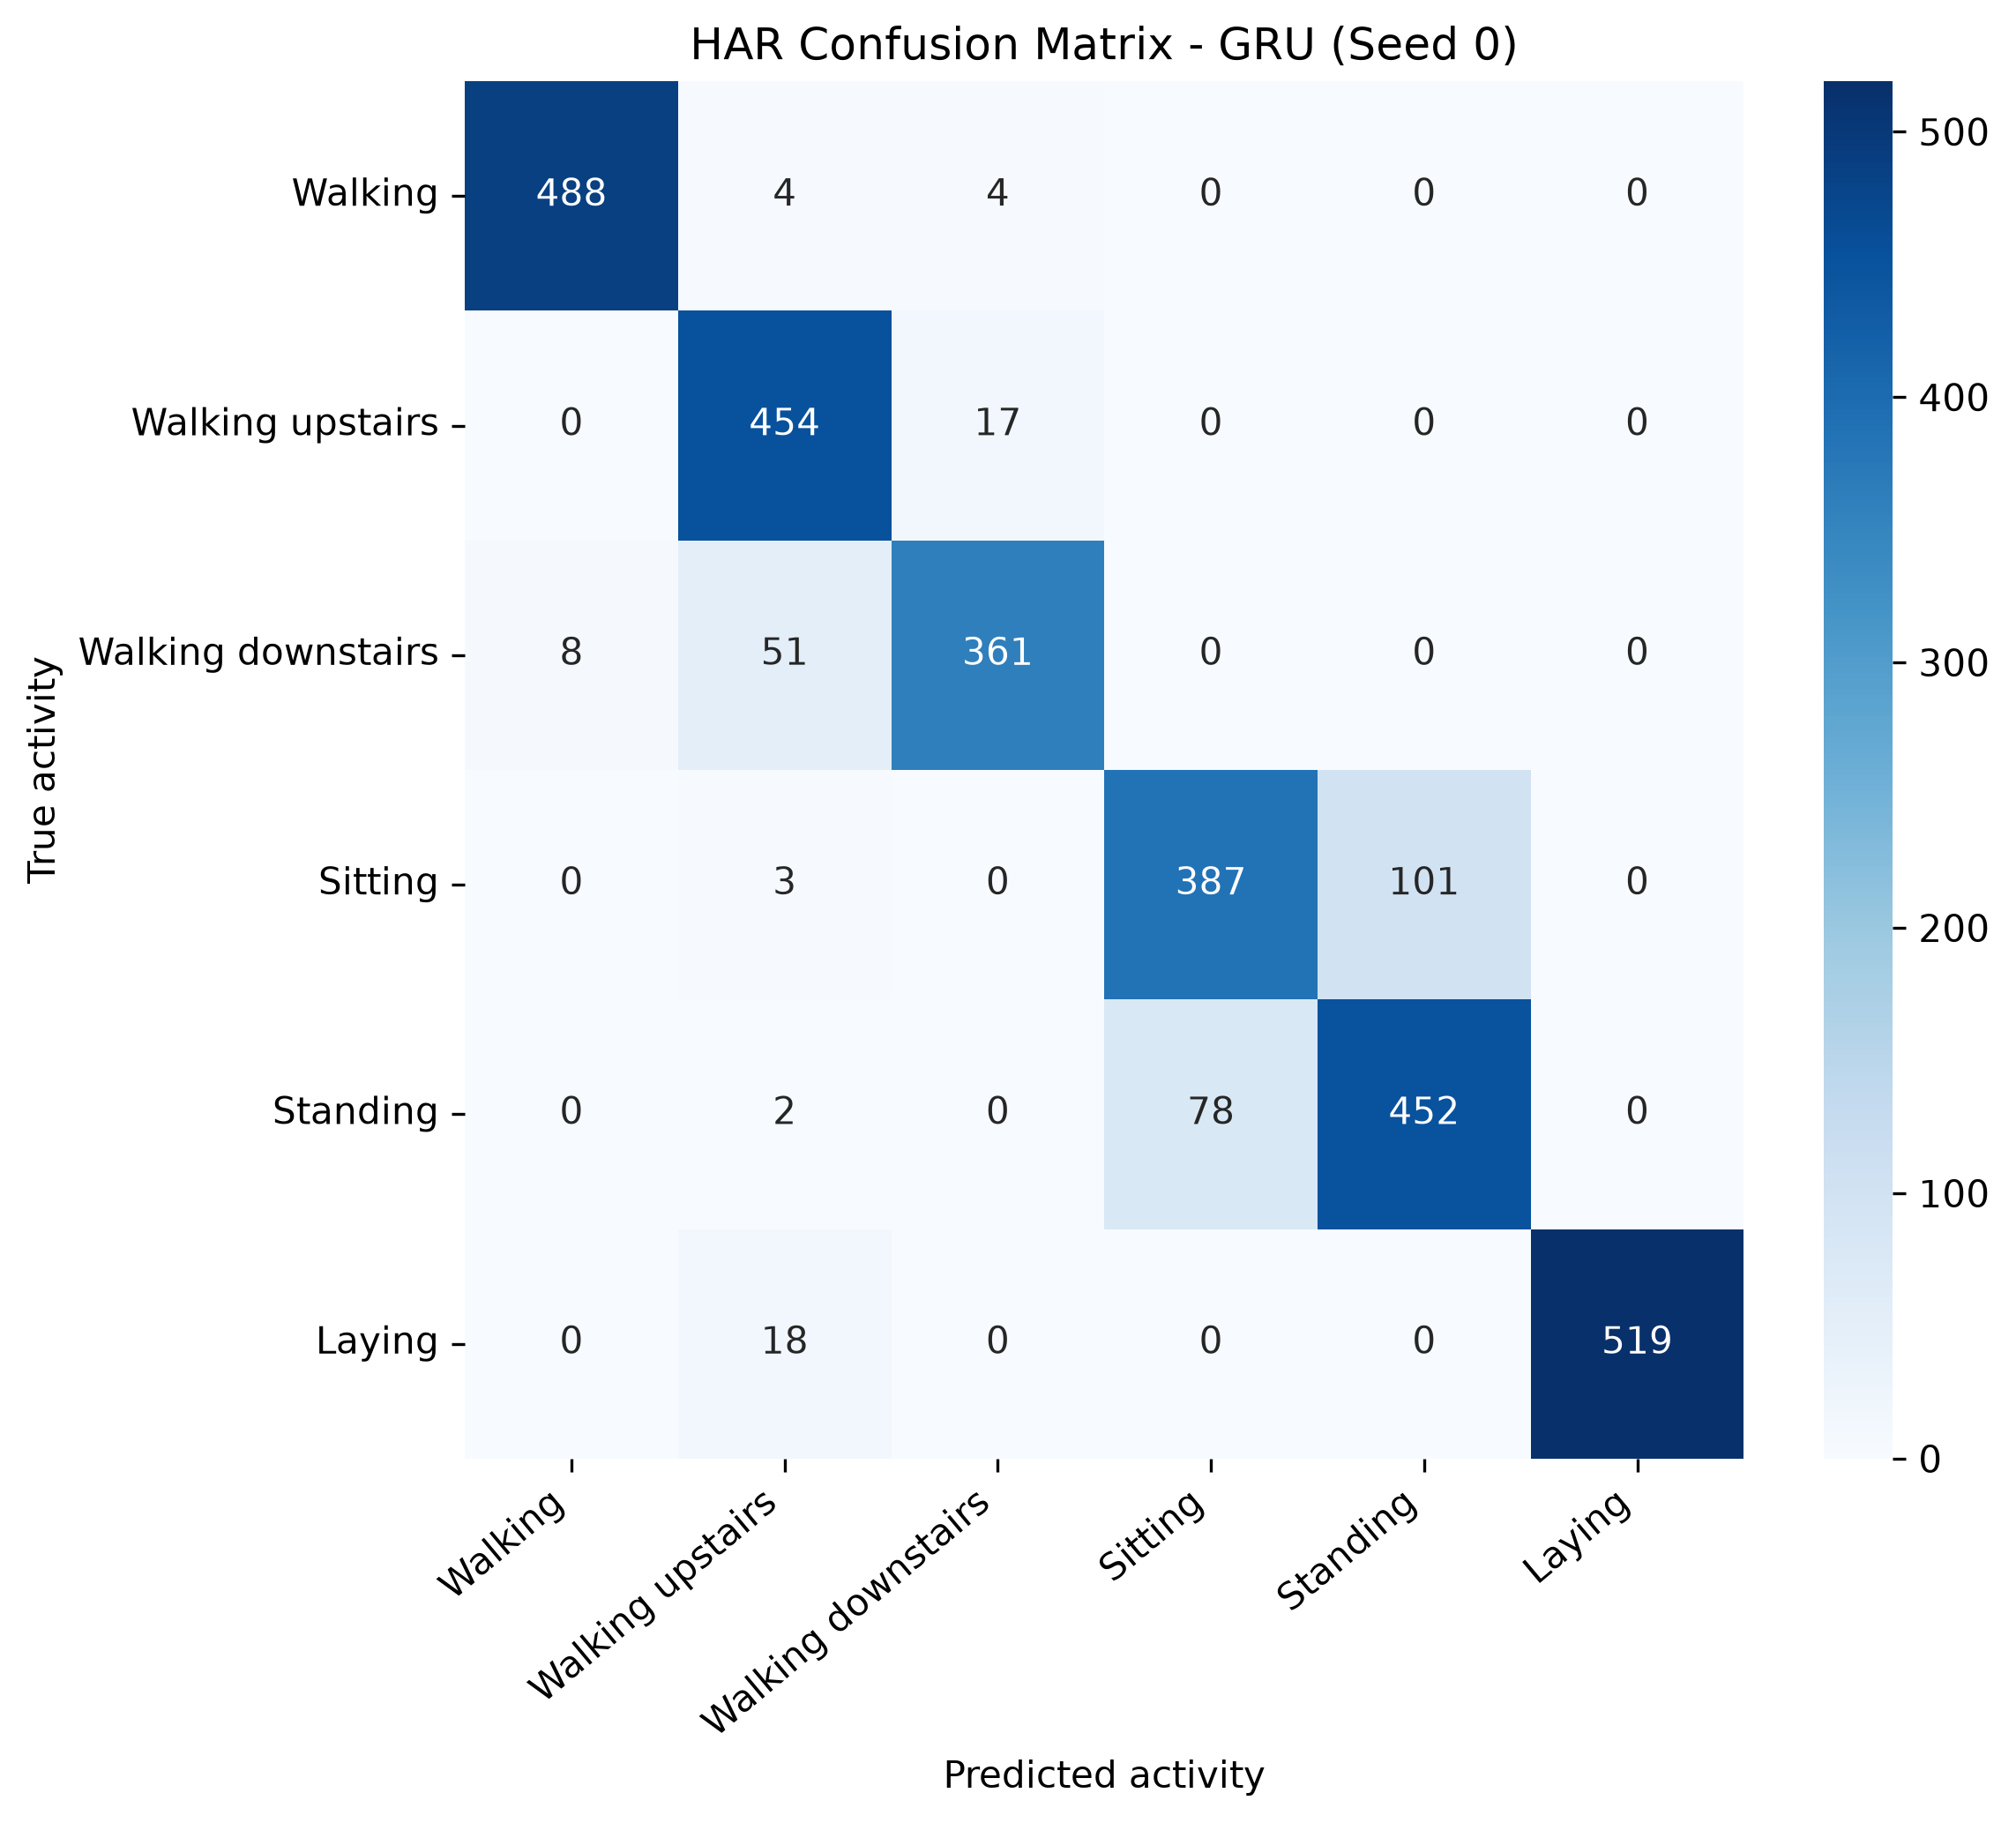

In [69]:
from pathlib import Path
from IPython.display import Image, display

confusion_matrix_file = Path(
    "figures/p1_figure_02_har_confusion_matrix.png"
)

assert confusion_matrix_file.exists(), (
    "Saved HAR confusion matrix was not found."
)

print("Using saved HAR confusion matrix from completed experiments.")

display(
    Image(
        filename=str(confusion_matrix_file)
    )
)

In [71]:
adding_summary = (
    adding_results_df
    .groupby(
        [
            "model",
            "seq_len"
        ]
    )
    .agg(
        mean_mse=(
            "test_mse",
            "mean"
        ),
        std_mse=(
            "test_mse",
            "std"
        ),
        solved_runs=(
            "solved",
            "sum"
        ),
        mean_sec_per_epoch=(
            "sec_per_epoch",
            "mean"
        )
    )
    .reset_index()
)

display(
    adding_summary
)

,model,seq_len,mean_mse,std_mse,solved_runs,mean_sec_per_epoch
0,GRU,50,0.001885,0.000548,3,3.912381
1,GRU,100,0.002276,0.000438,3,7.696857
2,GRU,200,0.001480,0.000201,3,15.490094
3,GRU,400,0.005106,0.002417,3,32.969107
4,LSTM,50,0.008159,0.003505,3,2.632823
5,LSTM,100,0.169495,0.000364,0,5.345452
6,LSTM,200,0.168401,0.000256,0,10.209436
7,LSTM,400,0.153716,0.000286,0,20.027523
8,RNN,50,0.172421,0.001270,0,1.611819
9,RNN,100,0.170115,0.000197,0,2.905231


In [72]:
assert len(adding_summary) == 12

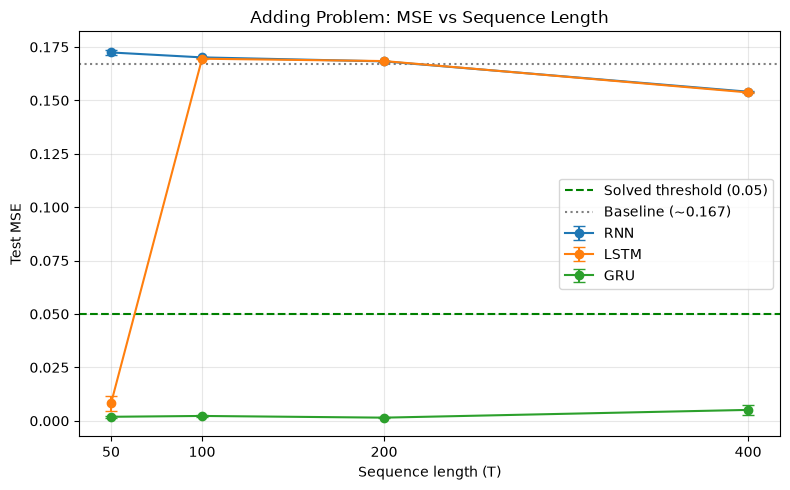

In [74]:
plt.figure(
    figsize=(8, 5)
)

for model_name in [
    "RNN",
    "LSTM",
    "GRU"
]:

    subset = adding_summary[
        adding_summary["model"]
        == model_name
    ]

    plt.errorbar(
        subset["seq_len"],
        subset["mean_mse"],
        yerr=subset["std_mse"],
        marker="o",
        capsize=4,
        label=model_name
    )

plt.axhline(
    y=0.05,
    color="green",
    linestyle="--",
    label="Solved threshold (0.05)"
)

plt.axhline(
    y=0.167,
    color="gray",
    linestyle=":",
    label="Baseline (~0.167)"
)

plt.xlabel(
    "Sequence length (T)"
)

plt.ylabel(
    "Test MSE"
)

plt.title(
    "Adding Problem: "
    "MSE vs Sequence Length"
)

plt.xticks(
    [50, 100, 200, 400]
)

plt.legend()

plt.grid(
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    "figures/p1_figure_03_mse_vs_sequence_length.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [91]:
adding_histories = {}

for model_type in ["rnn", "lstm", "gru"]:

    print("\n" + "=" * 60)
    print(f"Recreating history: {model_type.upper()}, T=200, seed=0")
    print("=" * 60)

    set_seed(0)

    train_loader, val_loader, _ = create_adding_loaders(
        T=200,
        batch_size=128
    )

    model = AddingRegressor(
        model_type=model_type,
        hidden_size=64
    ).to(device)

    model, run_history = train_adding_model(
        model=model,
        train_loader=train_loader,
        val_loader=val_loader,
        epochs=30,
        learning_rate=1e-3
    )

    adding_histories[
        (model_type, 200, 0)
    ] = run_history

print("\nT=200 histories recreated successfully.")


Recreating history: RNN, T=200, seed=0
Epoch 01/30 | train MSE 0.259966 | val MSE 0.161165 | 6.68s
Epoch 02/30 | train MSE 0.170205 | val MSE 0.163609 | 6.10s
Epoch 03/30 | train MSE 0.170059 | val MSE 0.162095 | 6.11s
Epoch 04/30 | train MSE 0.169133 | val MSE 0.162283 | 6.36s
Epoch 05/30 | train MSE 0.170158 | val MSE 0.160374 | 5.87s
Epoch 06/30 | train MSE 0.168949 | val MSE 0.159971 | 5.89s
Epoch 07/30 | train MSE 0.169451 | val MSE 0.159714 | 6.03s
Epoch 08/30 | train MSE 0.169493 | val MSE 0.161076 | 6.08s
Epoch 09/30 | train MSE 0.169821 | val MSE 0.159834 | 5.85s
Epoch 10/30 | train MSE 0.169962 | val MSE 0.159948 | 5.82s
Epoch 11/30 | train MSE 0.168834 | val MSE 0.159898 | 6.24s
Epoch 12/30 | train MSE 0.169465 | val MSE 0.160340 | 6.01s
Epoch 13/30 | train MSE 0.170202 | val MSE 0.159843 | 6.29s
Epoch 14/30 | train MSE 0.169838 | val MSE 0.159734 | 5.82s
Epoch 15/30 | train MSE 0.169451 | val MSE 0.159544 | 5.86s
Epoch 16/30 | train MSE 0.168742 | val MSE 0.159527 | 5.89s


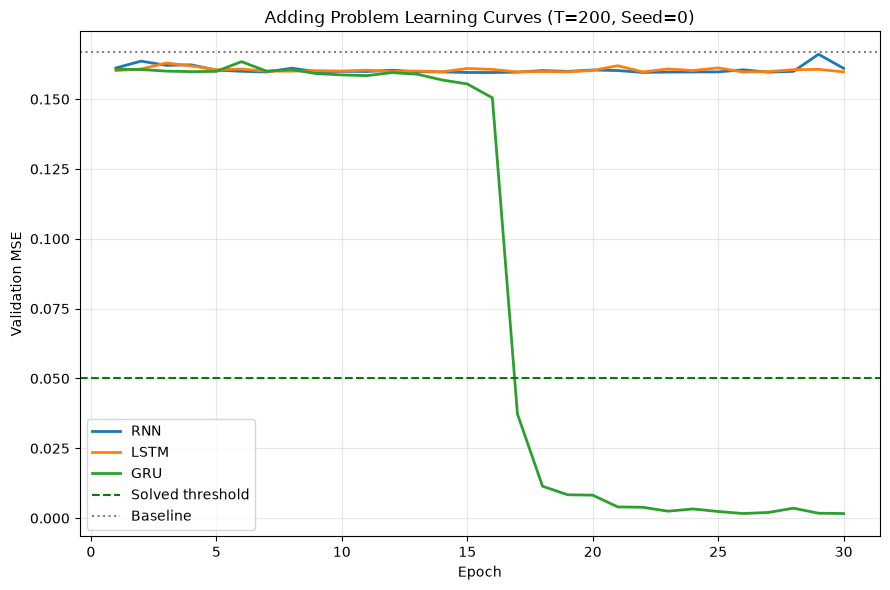

In [92]:
plt.figure(figsize=(9, 6))

for model_type in [
    "rnn",
    "lstm",
    "gru"
]:

    run_history = adding_histories[
        (model_type, 200, 0)
    ]

    epochs_range = range(
        1,
        len(run_history["val_mse"]) + 1
    )

    plt.plot(
        epochs_range,
        run_history["val_mse"],
        linewidth=2,
        label=model_type.upper()
    )

plt.axhline(
    0.05,
    linestyle="--",
    color="green",
    label="Solved threshold"
)

plt.axhline(
    0.167,
    linestyle=":",
    color="gray",
    label="Baseline"
)

plt.xlabel("Epoch")
plt.ylabel("Validation MSE")

plt.title(
    "Adding Problem Learning Curves "
    "(T=200, Seed=0)"
)

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    "figures/p1_figure_04_adding_T200_learning_curves.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

**Figure 4.** Validation MSE during training for RNN, LSTM, and GRU
on the adding problem with sequence length \(T=200\) and seed 0.
The solved threshold and reference baseline are shown for comparison.

In [94]:
print("Minimum MSE found:")

display(
    adding_results_df.nsmallest(
        10,
        "test_mse"
    )[
        [
            "model",
            "seed",
            "seq_len",
            "test_mse",
            "solved"
        ]
    ]
)

Minimum MSE found:


,model,seed,seq_len,test_mse,solved
31,GRU,1,200,0.001248,True
25,GRU,1,50,0.001274,True
30,GRU,0,200,0.001587,True
32,GRU,2,200,0.001605,True
28,GRU,1,100,0.001951,True
24,GRU,0,50,0.002051,True
29,GRU,2,100,0.002101,True
26,GRU,2,50,0.002331,True
27,GRU,0,100,0.002774,True
35,GRU,2,400,0.003204,True


In [95]:
print("\nBest result by model:")

display(
    adding_results_df.loc[
        adding_results_df
        .groupby("model")["test_mse"]
        .idxmin()
    ][
        [
            "model",
            "seed",
            "seq_len",
            "test_mse",
            "solved"
        ]
    ]
)


Best result by model:


,model,seed,seq_len,test_mse,solved
31,GRU,1,200,0.001248,True
14,LSTM,2,50,0.005481,True
11,RNN,2,400,0.153915,False


Task 5.	Gradients, ablations and analysis (15)  
o	(a) At T = 100 plot ‖∂L/∂h_t‖ against t on a log scale for the three models, before and after training.

## Gradient Analysis at T=100

The norm of the loss gradient with respect to each recurrent hidden
state is measured across the sequence:

\[
\left\|\frac{\partial L}{\partial h_t}\right\|_2.
\]

The analysis is performed before and after training for RNN, LSTM,
and GRU using sequence length \(T=100\). A logarithmic y-axis is used
to reveal vanishing-gradient behaviour.

In [97]:
class ManualAddingRegressor(nn.Module):

    def __init__(
        self,
        model_type,
        input_size=2,
        hidden_size=64
    ):
        super().__init__()

        self.model_type = model_type.lower()
        self.hidden_size = hidden_size

        if self.model_type == "rnn":
            self.cell = MyRNNCell(
                input_size,
                hidden_size
            )

        elif self.model_type == "lstm":
            self.cell = MyLSTMCell(
                input_size,
                hidden_size
            )

        elif self.model_type == "gru":
            self.cell = MyGRUCell(
                input_size,
                hidden_size
            )

        else:
            raise ValueError(
                "model_type must be rnn, lstm, or gru"
            )

        self.output_layer = nn.Linear(
            hidden_size,
            1
        )

    def forward(
        self,
        x,
        retain_hidden_gradients=False
    ):
        batch_size, sequence_length, _ = x.shape

        h_t = torch.zeros(
            batch_size,
            self.hidden_size,
            device=x.device,
            dtype=x.dtype
        )

        if self.model_type == "lstm":
            c_t = torch.zeros_like(h_t)

        hidden_states = []

        for timestep in range(sequence_length):

            x_t = x[:, timestep, :]

            if self.model_type == "lstm":
                h_t, c_t = self.cell(
                    x_t,
                    (h_t, c_t)
                )
            else:
                h_t = self.cell(
                    x_t,
                    h_t
                )

            if retain_hidden_gradients:
                h_t.retain_grad()

            hidden_states.append(h_t)

        prediction = self.output_layer(
            h_t
        ).squeeze(-1)

        if retain_hidden_gradients:
            return prediction, hidden_states

        return prediction

In [98]:
gradient_test_input = torch.randn(
    8,
    100,
    2
).to(device)

for model_type in ["rnn", "lstm", "gru"]:

    test_model = ManualAddingRegressor(
        model_type=model_type,
        hidden_size=64
    ).to(device)

    output = test_model(
        gradient_test_input
    )

    print(
        model_type.upper(),
        output.shape
    )

    assert output.shape == (8,)

print("Manual model shape tests passed.")

RNN torch.Size([8])
LSTM torch.Size([8])
GRU torch.Size([8])
Manual model shape tests passed.


In [99]:
def measure_hidden_gradients(
    model,
    X_batch,
    y_batch
):
    model.eval()
    model.zero_grad(set_to_none=True)

    X_batch = X_batch.to(device)
    y_batch = y_batch.to(device)

    predictions, hidden_states = model(
        X_batch,
        retain_hidden_gradients=True
    )

    loss = nn.functional.mse_loss(
        predictions,
        y_batch
    )

    loss.backward()

    gradient_norms = []

    for hidden_state in hidden_states:

        if hidden_state.grad is None:
            gradient_norms.append(0.0)
        else:
            sample_norms = hidden_state.grad.norm(
                p=2,
                dim=1
            )

            gradient_norms.append(
                sample_norms.mean().item()
            )

    return (
        np.array(gradient_norms),
        loss.item()
    )

In [100]:
gradient_train_loader, gradient_val_loader, _ = (
    create_adding_loaders(
        T=100,
        batch_size=128
    )
)

gradient_X, gradient_y = next(
    iter(gradient_val_loader)
)

print("Gradient batch X:", gradient_X.shape)
print("Gradient batch y:", gradient_y.shape)

assert gradient_X.shape == (128, 100, 2)


Gradient batch X: torch.Size([128, 100, 2])
Gradient batch y: torch.Size([128])


In [101]:
gradient_results = {}
gradient_histories = {}

for model_type in ["rnn", "lstm", "gru"]:

    print("\n" + "=" * 65)
    print(
        f"Gradient analysis: "
        f"{model_type.upper()}, T=100"
    )
    print("=" * 65)

    set_seed(0)

    model = ManualAddingRegressor(
        model_type=model_type,
        hidden_size=64
    ).to(device)

    before_norms, before_loss = (
        measure_hidden_gradients(
            model,
            gradient_X,
            gradient_y
        )
    )

    model, run_history = train_adding_model(
        model=model,
        train_loader=gradient_train_loader,
        val_loader=gradient_val_loader,
        epochs=30,
        learning_rate=1e-3
    )

    after_norms, after_loss = (
        measure_hidden_gradients(
            model,
            gradient_X,
            gradient_y
        )
    )

    gradient_results[model_type] = {
        "before": before_norms,
        "after": after_norms,
        "before_loss": before_loss,
        "after_loss": after_loss
    }

    gradient_histories[model_type] = run_history

    print(
        f"Loss before: {before_loss:.6f}"
    )
    print(
        f"Loss after:  {after_loss:.6f}"
    )


Gradient analysis: RNN, T=100
Epoch 01/30 | train MSE 0.257395 | val MSE 0.161697 | 4.63s
Epoch 02/30 | train MSE 0.168941 | val MSE 0.161136 | 4.88s
Epoch 03/30 | train MSE 0.168245 | val MSE 0.160797 | 3.77s
Epoch 04/30 | train MSE 0.167511 | val MSE 0.161156 | 3.83s
Epoch 05/30 | train MSE 0.167134 | val MSE 0.160540 | 5.58s
Epoch 06/30 | train MSE 0.167641 | val MSE 0.160687 | 4.29s
Epoch 07/30 | train MSE 0.167609 | val MSE 0.160572 | 3.95s
Epoch 08/30 | train MSE 0.167701 | val MSE 0.161527 | 4.09s
Epoch 09/30 | train MSE 0.167902 | val MSE 0.161157 | 4.07s
Epoch 10/30 | train MSE 0.167837 | val MSE 0.168261 | 4.42s
Epoch 11/30 | train MSE 0.169183 | val MSE 0.160945 | 3.99s
Epoch 12/30 | train MSE 0.167176 | val MSE 0.160509 | 4.13s
Epoch 13/30 | train MSE 0.167438 | val MSE 0.160508 | 4.69s
Epoch 14/30 | train MSE 0.167290 | val MSE 0.160532 | 4.35s
Epoch 15/30 | train MSE 0.167137 | val MSE 0.160361 | 3.85s
Epoch 16/30 | train MSE 0.167256 | val MSE 0.160939 | 4.56s
Epoch 17/

In [102]:
gradient_rows = []

for model_type, result in gradient_results.items():

    for timestep in range(100):

        gradient_rows.append({
            "model": model_type.upper(),
            "timestep": timestep + 1,
            "before_training":
                result["before"][timestep],
            "after_training":
                result["after"][timestep]
        })

gradient_df = pd.DataFrame(
    gradient_rows
)

gradient_df.to_csv(
    "gradient_analysis_T100.csv",
    index=False
)

display(gradient_df.head())

,model,timestep,before_training,after_training
0,RNN,1,0.024492,0.000024
1,RNN,2,0.022455,0.000021
2,RNN,3,0.020366,0.000018
3,RNN,4,0.018817,0.000017
4,RNN,5,0.017886,0.000016


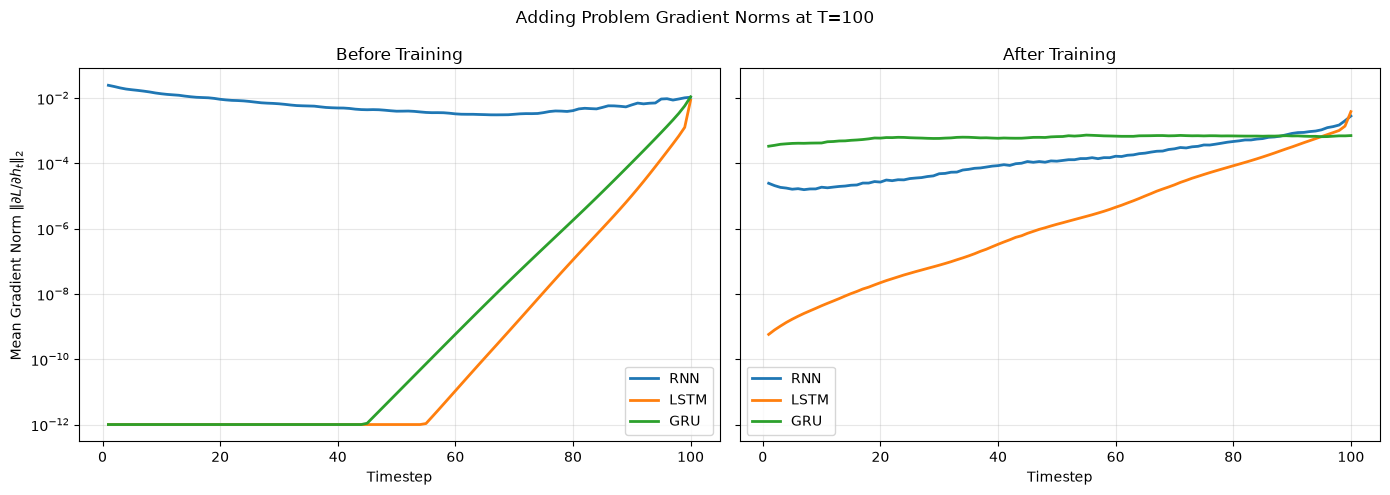

In [103]:
figure, axes = plt.subplots(
    1,
    2,
    figsize=(14, 5),
    sharey=True
)

timesteps = np.arange(1, 101)

minimum_positive = 1e-12

for model_type in ["rnn", "lstm", "gru"]:

    before_values = np.maximum(
        gradient_results[model_type]["before"],
        minimum_positive
    )

    after_values = np.maximum(
        gradient_results[model_type]["after"],
        minimum_positive
    )

    axes[0].plot(
        timesteps,
        before_values,
        linewidth=2,
        label=model_type.upper()
    )

    axes[1].plot(
        timesteps,
        after_values,
        linewidth=2,
        label=model_type.upper()
    )

axes[0].set_title("Before Training")
axes[1].set_title("After Training")

for axis in axes:
    axis.set_yscale("log")
    axis.set_xlabel("Timestep")
    axis.grid(alpha=0.3)
    axis.legend()

axes[0].set_ylabel(
    r"Mean Gradient Norm "
    r"$\|\partial L/\partial h_t\|_2$"
)

figure.suptitle(
    "Adding Problem Gradient Norms at T=100"
)

figure.tight_layout()

figure.savefig(
    "figures/p1_figure_05_gradient_norms_T100.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

**Figure 5.** Mean hidden-state gradient norm across timesteps for
RNN, LSTM, and GRU on the adding problem at \(T=100\), before and
after training. The logarithmic y-axis highlights differences in
gradient propagation over long temporal distances.

o	(b) Hidden-size sweep {16, 32, 64, 128} for LSTM and GRU on HAR.

## Hidden-Size Sweep on UCI HAR

LSTM and GRU are compared using hidden sizes 16, 32, 64, and 128.
The optimizer, learning rate, batch size, epoch budget, subject-wise
validation procedure, and three random seeds remain unchanged.

In [23]:
from pathlib import Path

HIDDEN_SIZES = [16, 32, 64, 128]
SWEEP_MODELS = ["lstm", "gru"]
SWEEP_SEEDS = [0, 1, 2]

sweep_file = Path(
    "hidden_size_sweep_temp.csv"
)

if sweep_file.exists():
    hidden_sweep_df = pd.read_csv(
        sweep_file
    )

    hidden_sweep_results = (
        hidden_sweep_df.to_dict("records")
    )

    print(
        "Restored completed sweep runs:",
        len(hidden_sweep_results)
    )
else:
    hidden_sweep_results = []

completed_keys = {
    (
        str(row["model"]).lower(),
        int(row["hidden_size"]),
        int(row["seed"])
    )
    for row in hidden_sweep_results
}

Restored completed sweep runs: 8


In [31]:
for model_type in SWEEP_MODELS:

    for hidden_size in HIDDEN_SIZES:

        for seed in SWEEP_SEEDS:

            key = (
                model_type,
                hidden_size,
                seed
            )

            if key in completed_keys:
                print("Skipping completed:", key)
                continue

            (
                result,
                _,
                _,
                _,
                _
            ) = run_har_experiment(
                model_type=model_type,
                seed=seed,
                hidden_size=hidden_size,
                batch_size=64,
                epochs=30,
                learning_rate=1e-3
            )

            result["hidden_size"] = hidden_size

            hidden_sweep_results.append(
                result
            )

            completed_keys.add(key)

            pd.DataFrame(
                hidden_sweep_results
            ).to_csv(
                sweep_file,
                index=False
            )

print("Hidden-size sweep complete.")

Skipping completed: ('lstm', 16, 0)
Skipping completed: ('lstm', 16, 1)
Skipping completed: ('lstm', 16, 2)
Skipping completed: ('lstm', 32, 0)
Skipping completed: ('lstm', 32, 1)
Skipping completed: ('lstm', 32, 2)
Skipping completed: ('lstm', 64, 0)
Skipping completed: ('lstm', 64, 1)

Model: LSTM | Seed: 2
Epoch 01/30 | train loss 1.2584 | val loss 1.1610 | val acc 0.5633 | val F1 0.5151 | 5.80s
Epoch 02/30 | train loss 0.7727 | val loss 0.6912 | val acc 0.7393 | val F1 0.7328 | 5.18s
Epoch 03/30 | train loss 0.5409 | val loss 0.6198 | val acc 0.7543 | val F1 0.7483 | 4.48s
Epoch 04/30 | train loss 0.9287 | val loss 0.8255 | val acc 0.6434 | val F1 0.6392 | 4.45s
Epoch 05/30 | train loss 0.5901 | val loss 0.5869 | val acc 0.7581 | val F1 0.7567 | 4.72s
Epoch 06/30 | train loss 0.3855 | val loss 0.5033 | val acc 0.7798 | val F1 0.7698 | 4.66s
Epoch 07/30 | train loss 0.4366 | val loss 0.6971 | val acc 0.7191 | val F1 0.6638 | 4.55s
Epoch 08/30 | train loss 0.3820 | val loss 0.5443 | 

In [32]:
duplicates = hidden_sweep_df.duplicated(
    subset=[
        "model",
        "hidden_size",
        "seed"
    ],
    keep=False
)

print(
    "Duplicate configurations:",
    duplicates.sum()
)

if duplicates.any():
    display(
        hidden_sweep_df[
            duplicates
        ].sort_values(
            [
                "model",
                "hidden_size",
                "seed"
            ]
        )
    )

Duplicate configurations: 0


In [34]:
hidden_sweep_df = pd.DataFrame(
    hidden_sweep_results
)

print(
    "Completed hidden-size runs:",
    len(hidden_sweep_df)
)

assert len(hidden_sweep_df) == 24

display(
    hidden_sweep_df[
        [
            "model",
            "hidden_size",
            "seed",
            "test_acc",
            "macro_f1",
            "params",
            "sec_per_epoch"
        ]
    ]
)

Completed hidden-size runs: 24


,model,hidden_size,seed,test_acc,macro_f1,params,sec_per_epoch
0,LSTM,16,0,0.855786,0.855094,1830,1.465865
1,LSTM,16,1,0.739396,0.719667,1830,1.441418
2,LSTM,16,2,0.856125,0.855283,1830,1.408579
3,LSTM,32,0,0.819477,0.815509,5702,2.234244
4,LSTM,32,1,0.889379,0.889407,5702,2.289822
5,LSTM,32,2,0.885307,0.885466,5702,2.275035
6,LSTM,64,0,0.898880,0.900234,19590,4.412617
7,LSTM,64,1,0.888022,0.887658,19590,4.422262
8,LSTM,64,2,0.864269,0.853846,19590,4.580924
9,LSTM,128,0,0.898880,0.899687,71942,12.845725


In [35]:
hidden_sweep_summary = (
    hidden_sweep_df
    .groupby(
        ["model", "hidden_size"]
    )
    .agg(
        test_acc_mean=("test_acc", "mean"),
        test_acc_std=("test_acc", "std"),
        macro_f1_mean=("macro_f1", "mean"),
        macro_f1_std=("macro_f1", "std"),
        params=("params", "first"),
        sec_per_epoch_mean=(
            "sec_per_epoch",
            "mean"
        )
    )
    .reset_index()
)

display(hidden_sweep_summary)

assert len(hidden_sweep_summary) == 8

,model,hidden_size,test_acc_mean,test_acc_std,macro_f1_mean,macro_f1_std,params,sec_per_epoch_mean
0,GRU,16,0.880443,0.004519,0.880005,0.005034,1398,6.235715
1,GRU,32,0.892094,0.023721,0.891966,0.024355,4326,7.401355
2,GRU,64,0.894808,0.007341,0.894873,0.006979,14790,9.862203
3,GRU,128,0.898767,0.008733,0.898971,0.008501,54150,17.362141
4,LSTM,16,0.817102,0.067296,0.810014,0.078244,1830,1.438621
5,LSTM,32,0.864721,0.039235,0.863461,0.041574,5702,2.266367
6,LSTM,64,0.883724,0.017702,0.880580,0.023991,19590,4.471934
7,LSTM,128,0.892433,0.006284,0.892562,0.006928,71942,12.820771


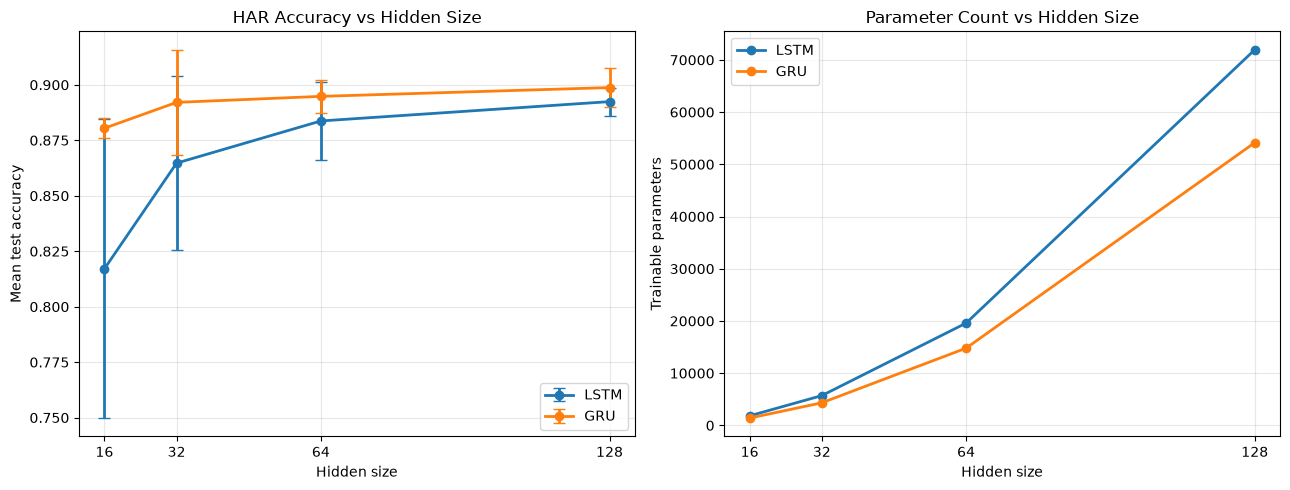

In [36]:
figure, axes = plt.subplots(
    1,
    2,
    figsize=(13, 5)
)

for model_name in ["LSTM", "GRU"]:

    subset = (
        hidden_sweep_summary[
            hidden_sweep_summary["model"]
            == model_name
        ]
        .sort_values("hidden_size")
    )

    axes[0].errorbar(
        subset["hidden_size"],
        subset["test_acc_mean"],
        yerr=subset["test_acc_std"],
        marker="o",
        capsize=4,
        linewidth=2,
        label=model_name
    )

    axes[1].plot(
        subset["hidden_size"],
        subset["params"],
        marker="o",
        linewidth=2,
        label=model_name
    )

axes[0].set_title("HAR Accuracy vs Hidden Size")
axes[0].set_xlabel("Hidden size")
axes[0].set_ylabel("Mean test accuracy")
axes[0].set_xticks(HIDDEN_SIZES)
axes[0].grid(alpha=0.3)
axes[0].legend()

axes[1].set_title("Parameter Count vs Hidden Size")
axes[1].set_xlabel("Hidden size")
axes[1].set_ylabel("Trainable parameters")
axes[1].set_xticks(HIDDEN_SIZES)
axes[1].grid(alpha=0.3)
axes[1].legend()

figure.tight_layout()

figure.savefig(
    "figures/p1_figure_06_hidden_size_sweep.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

**Figure 6.** HAR test accuracy and parameter count for LSTM and GRU
as hidden size increases from 16 to 128. Accuracy error bars represent
the standard deviation across three random seeds.

o	(c) Individual ablation, chosen by the last digit of your student ID (see Individualisation): even = gradient clipping (norm 1.0 versus none) for the vanilla RNN at T = 200; odd = LSTM forget-gate bias initialised to 0 versus 1 at T = 200.

## Individual Ablation: LSTM Forget-Gate Bias

Because the final digit of student ID 2026AJ05601 is odd, the assigned
ablation compares LSTM forget-gate bias initialization values 0 and 1
on the adding problem at \(T=200\).

A positive forget-gate bias initially encourages the model to retain
more of the previous cell state.

In [55]:
class ForgetBiasLSTMRegressor(nn.Module):

    def __init__(
        self,
        hidden_size=64,
        forget_bias=0.0
    ):
        super().__init__()

        self.hidden_size = hidden_size
        self.forget_bias = float(
            forget_bias
        )

        self.recurrent = nn.LSTM(
            input_size=2,
            hidden_size=hidden_size,
            batch_first=True
        )

        self.output_layer = nn.Linear(
            hidden_size,
            1
        )

        self.reset_parameters()

    def reset_parameters(self):

        # Preserve PyTorch's normal weight initialization.
        self.recurrent.reset_parameters()
        self.output_layer.reset_parameters()

        with torch.no_grad():

            # PyTorch has two bias vectors. Keep the recurrent
            # bias zero and place the full requested forget bias
            # in bias_ih_l0.
            self.recurrent.bias_ih_l0.zero_()
            self.recurrent.bias_hh_l0.zero_()

            start = self.hidden_size
            end = 2 * self.hidden_size

            self.recurrent.bias_ih_l0[
                start:end
            ].fill_(
                self.forget_bias
            )

    def forward(self, x):

        output, _ = self.recurrent(x)

        final_hidden = output[:, -1, :]

        prediction = self.output_layer(
            final_hidden
        ).squeeze(-1)

        return prediction

In [56]:
for bias_value in [0.0, 1.0]:

    test_model = ForgetBiasLSTMRegressor(
        hidden_size=64,
        forget_bias=bias_value
    )

    forget_slice = (
        test_model
        .recurrent
        .bias_ih_l0[64:128]
    )

    print(
        f"Requested bias {bias_value}:",
        "mean =",
        forget_slice.mean().item()
    )

    assert torch.allclose(
        forget_slice,
        torch.full_like(
            forget_slice,
            bias_value
        )
    )

print("Forget-bias initialization tests passed.")

Requested bias 0.0: mean = 0.0
Requested bias 1.0: mean = 1.0
Forget-bias initialization tests passed.


In [57]:
forget_bias_results = []
forget_bias_histories = {}

for forget_bias in [0.0, 1.0]:

    for seed in [0, 1, 2]:

        print("\n" + "=" * 65)
        print(
            f"Forget bias={forget_bias} | "
            f"T=200 | Seed={seed}"
        )
        print("=" * 65)

        set_seed(seed)

        train_loader, val_loader, test_loader = (
            create_adding_loaders(
                T=200,
                batch_size=128
            )
        )

        model = ForgetBiasLSTMRegressor(
            hidden_size=64,
            forget_bias=forget_bias
        ).to(device)

        parameter_count = sum(
            parameter.numel()
            for parameter in model.parameters()
        )

        model, run_history = train_adding_model(
            model=model,
            train_loader=train_loader,
            val_loader=val_loader,
            epochs=30,
            learning_rate=1e-3
        )

        test_mse = evaluate_adding(
            model,
            test_loader
        )

        row = {
            "forget_bias": forget_bias,
            "seed": seed,
            "seq_len": 200,
            "test_mse": test_mse,
            "solved": test_mse < 0.05,
            "params": parameter_count,
            "sec_per_epoch": np.mean(
                run_history["epoch_seconds"]
            )
        }

        forget_bias_results.append(row)

        forget_bias_histories[
            (forget_bias, seed)
        ] = run_history

        pd.DataFrame(
            forget_bias_results
        ).to_csv(
            "forget_bias_ablation_temp.csv",
            index=False
        )

        print(
            f"Test MSE: {test_mse:.6f} | "
            f"Solved: {test_mse < 0.05}"
        )


Forget bias=0.0 | T=200 | Seed=0
Epoch 01/30 | train MSE 0.423775 | val MSE 0.160788 | 11.49s
Epoch 02/30 | train MSE 0.169899 | val MSE 0.160594 | 11.60s
Epoch 03/30 | train MSE 0.169850 | val MSE 0.160378 | 11.46s
Epoch 04/30 | train MSE 0.170299 | val MSE 0.160533 | 10.70s
Epoch 05/30 | train MSE 0.169481 | val MSE 0.160201 | 12.22s
Epoch 06/30 | train MSE 0.169570 | val MSE 0.160197 | 14.33s
Epoch 07/30 | train MSE 0.169070 | val MSE 0.160176 | 11.21s
Epoch 08/30 | train MSE 0.168824 | val MSE 0.159914 | 11.52s
Epoch 09/30 | train MSE 0.168756 | val MSE 0.161321 | 11.35s
Epoch 10/30 | train MSE 0.168955 | val MSE 0.160046 | 10.96s
Epoch 11/30 | train MSE 0.169561 | val MSE 0.159911 | 11.29s
Epoch 12/30 | train MSE 0.169300 | val MSE 0.159982 | 11.26s
Epoch 13/30 | train MSE 0.169531 | val MSE 0.160905 | 11.47s
Epoch 14/30 | train MSE 0.169005 | val MSE 0.159803 | 11.14s
Epoch 15/30 | train MSE 0.169056 | val MSE 0.162274 | 11.16s
Epoch 16/30 | train MSE 0.168888 | val MSE 0.159886

In [58]:
forget_bias_df = pd.DataFrame(
    forget_bias_results
)

assert len(forget_bias_df) == 6

forget_bias_summary = (
    forget_bias_df
    .groupby("forget_bias")
    .agg(
        mean_mse=("test_mse", "mean"),
        std_mse=("test_mse", "std"),
        solved_runs=("solved", "sum"),
        mean_sec_per_epoch=(
            "sec_per_epoch",
            "mean"
        )
    )
    .reset_index()
)

display(forget_bias_df)
display(forget_bias_summary)

,forget_bias,seed,seq_len,test_mse,solved,params,sec_per_epoch
0,0.0,0,200,0.168447,False,17473,11.187783
1,0.0,1,200,0.168419,False,17473,11.490068
2,0.0,2,200,0.168875,False,17473,11.063082
3,1.0,0,200,0.168603,False,17473,10.756486
4,1.0,1,200,0.168554,False,17473,10.706731
5,1.0,2,200,0.168439,False,17473,10.635136


,forget_bias,mean_mse,std_mse,solved_runs,mean_sec_per_epoch
0,0.0,0.168581,0.000256,0,11.246977
1,1.0,0.168532,0.000084,0,10.699451


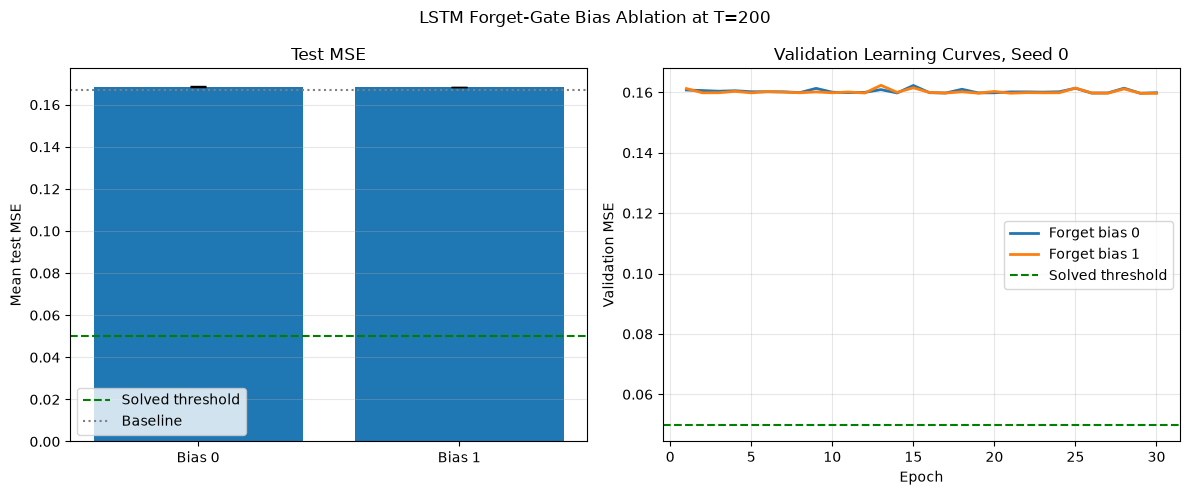

In [59]:
figure, axes = plt.subplots(
    1,
    2,
    figsize=(12, 5)
)

bias_labels = [
    f"Bias {value:g}"
    for value in forget_bias_summary[
        "forget_bias"
    ]
]

axes[0].bar(
    bias_labels,
    forget_bias_summary["mean_mse"],
    yerr=forget_bias_summary["std_mse"],
    capsize=6
)

axes[0].axhline(
    0.05,
    color="green",
    linestyle="--",
    label="Solved threshold"
)

axes[0].axhline(
    0.167,
    color="gray",
    linestyle=":",
    label="Baseline"
)

axes[0].set_title("Test MSE")
axes[0].set_ylabel("Mean test MSE")
axes[0].legend()
axes[0].grid(axis="y", alpha=0.3)

for forget_bias in [0.0, 1.0]:

    history = forget_bias_histories[
        (forget_bias, 0)
    ]

    epochs_range = range(
        1,
        len(history["val_mse"]) + 1
    )

    axes[1].plot(
        epochs_range,
        history["val_mse"],
        linewidth=2,
        label=f"Forget bias {forget_bias:g}"
    )

axes[1].axhline(
    0.05,
    color="green",
    linestyle="--",
    label="Solved threshold"
)

axes[1].set_title(
    "Validation Learning Curves, Seed 0"
)

axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Validation MSE")
axes[1].legend()
axes[1].grid(alpha=0.3)

figure.suptitle(
    "LSTM Forget-Gate Bias Ablation at T=200"
)

figure.tight_layout()

figure.savefig(
    "figures/p1_figure_07_forget_bias_ablation.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

**Figure 7.** LSTM forget-gate bias ablation on the adding problem at
\(T=200\). The left panel shows mean test MSE across three seeds, and
the right panel compares validation learning curves for seed 0.

In [60]:
from pathlib import Path

required_figures = [
    "figures/p1_figure_01_har_class_balance.png",
    "figures/p1_figure_02_har_confusion_matrix.png",
    "figures/p1_figure_03_mse_vs_sequence_length.png",
    "figures/p1_figure_04_adding_T200_learning_curves.png",
    "figures/p1_figure_05_gradient_norms_T100.png",
    "figures/p1_figure_06_hidden_size_sweep.png",
    "figures/p1_figure_07_forget_bias_ablation.png"
]

for filename in required_figures:

    exists = Path(filename).exists()

    print(
        f"{'OK' if exists else 'MISSING':8s}",
        filename
    )

OK       figures/p1_figure_01_har_class_balance.png
OK       figures/p1_figure_02_har_confusion_matrix.png
OK       figures/p1_figure_03_mse_vs_sequence_length.png
OK       figures/p1_figure_04_adding_T200_learning_curves.png
OK       figures/p1_figure_05_gradient_norms_T100.png
OK       figures/p1_figure_06_hidden_size_sweep.png
OK       figures/p1_figure_07_forget_bias_ablation.png


In [61]:
required_result_files = [
    "har_results_temp.csv",
    "adding_results_temp.csv",
    "gradient_analysis_T100.csv",
    "hidden_size_sweep_temp.csv",
    "forget_bias_ablation_temp.csv"
]

for filename in required_result_files:

    exists = Path(filename).exists()

    print(
        f"{'OK' if exists else 'MISSING':8s}",
        filename
    )

OK       har_results_temp.csv
OK       adding_results_temp.csv
OK       gradient_analysis_T100.csv
OK       hidden_size_sweep_temp.csv
OK       forget_bias_ablation_temp.csv


o	(d) One-page analysis: what the gradient plot says about memory, where each model fails as T grows, the accuracy–parameters–time trade-off, and which model you would put on a battery-powered wearable, with reasons taken from your tables.

In [62]:
import pandas as pd
import numpy as np
from pathlib import Path

# Load saved experimental results
har_results_df = pd.read_csv(
    "har_results_temp.csv"
)

adding_results_df = pd.read_csv(
    "adding_results_temp.csv"
)

hidden_sweep_df = pd.read_csv(
    "hidden_size_sweep_temp.csv"
)

forget_bias_df = pd.read_csv(
    "forget_bias_ablation_temp.csv"
)

print("Loaded:")
print("HAR runs:", len(har_results_df))
print("Adding runs:", len(adding_results_df))
print("Hidden-size runs:", len(hidden_sweep_df))
print("Forget-bias runs:", len(forget_bias_df))


Loaded:
HAR runs: 9
Adding runs: 36
Hidden-size runs: 24
Forget-bias runs: 6


In [63]:
har_summary_d = (
    har_results_df
    .groupby("model")
    .agg(
        accuracy_mean=("test_acc", "mean"),
        accuracy_std=("test_acc", "std"),
        f1_mean=("macro_f1", "mean"),
        f1_std=("macro_f1", "std"),
        params=("params", "first"),
        sec_epoch=("sec_per_epoch", "mean")
    )
    .reset_index()
)

print("\n===== HAR MODEL COMPARISON =====\n")

for _, row in har_summary_d.iterrows():

    print(f"{row['model']}")
    
    print(
        f"  Accuracy : "
        f"{row['accuracy_mean']:.4f} "
        f"± {row['accuracy_std']:.4f}"
    )

    print(
        f"  Macro-F1 : "
        f"{row['f1_mean']:.4f} "
        f"± {row['f1_std']:.4f}"
    )

    print(
        f"  Parameters: "
        f"{int(row['params']):,}"
    )

    print(
        f"  Sec/epoch : "
        f"{row['sec_epoch']:.2f}"
    )

    print()


===== HAR MODEL COMPARISON =====

GRU
  Accuracy : 0.8948 ± 0.0073
  Macro-F1 : 0.8949 ± 0.0070
  Parameters: 14,790
  Sec/epoch : 8.94

LSTM
  Accuracy : 0.8837 ± 0.0177
  Macro-F1 : 0.8806 ± 0.0240
  Parameters: 19,590
  Sec/epoch : 4.41

RNN
  Accuracy : 0.7465 ± 0.0427
  Macro-F1 : 0.7365 ± 0.0499
  Parameters: 5,190
  Sec/epoch : 3.53



In [64]:
adding_summary_d = (
    adding_results_df
    .groupby(
        ["model", "seq_len"]
    )
    .agg(
        mse_mean=("test_mse", "mean"),
        mse_std=("test_mse", "std"),
        solved_runs=("solved", "sum")
    )
    .reset_index()
)

print("\n===== ADDING PROBLEM =====\n")

for model in ["RNN", "LSTM", "GRU"]:

    print(model)
    print("-" * 55)

    subset = (
        adding_summary_d[
            adding_summary_d["model"] == model
        ]
        .sort_values("seq_len")
    )

    for _, row in subset.iterrows():

        print(
            f"T={int(row['seq_len']):3d} | "
            f"MSE={row['mse_mean']:.6f} "
            f"± {row['mse_std']:.6f} | "
            f"Solved={int(row['solved_runs'])}/3"
        )

    print()



===== ADDING PROBLEM =====

RNN
-------------------------------------------------------
T= 50 | MSE=0.172421 ± 0.001270 | Solved=0/3
T=100 | MSE=0.170115 ± 0.000197 | Solved=0/3
T=200 | MSE=0.168249 ± 0.000221 | Solved=0/3
T=400 | MSE=0.154049 ± 0.000205 | Solved=0/3

LSTM
-------------------------------------------------------
T= 50 | MSE=0.008159 ± 0.003505 | Solved=3/3
T=100 | MSE=0.169495 ± 0.000364 | Solved=0/3
T=200 | MSE=0.168401 ± 0.000256 | Solved=0/3
T=400 | MSE=0.153716 ± 0.000286 | Solved=0/3

GRU
-------------------------------------------------------
T= 50 | MSE=0.001885 ± 0.000548 | Solved=3/3
T=100 | MSE=0.002276 ± 0.000438 | Solved=3/3
T=200 | MSE=0.001480 ± 0.000201 | Solved=3/3
T=400 | MSE=0.005106 ± 0.002417 | Solved=3/3



In [66]:
print("\n===== SOLVED-RUN ANALYSIS =====\n")

for model in ["RNN", "LSTM", "GRU"]:

    subset = (
        adding_summary_d[
            adding_summary_d["model"] == model
        ]
        .sort_values("seq_len")
    )

    print(model)

    for _, row in subset.iterrows():

        T = int(row["seq_len"])
        solved = int(row["solved_runs"])

        if solved == 3:
            status = "all seeds solved"

        elif solved > 0:
            status = f"{solved}/3 seeds solved"

        else:
            status = "no seeds solved"

        print(
            f"  T={T}: {status}"
        )

    print()


===== SOLVED-RUN ANALYSIS =====

RNN
  T=50: no seeds solved
  T=100: no seeds solved
  T=200: no seeds solved
  T=400: no seeds solved

LSTM
  T=50: all seeds solved
  T=100: no seeds solved
  T=200: no seeds solved
  T=400: no seeds solved

GRU
  T=50: all seeds solved
  T=100: all seeds solved
  T=200: all seeds solved
  T=400: all seeds solved



In [67]:
hidden_summary_d = (
    hidden_sweep_df
    .groupby(
        ["model", "hidden_size"]
    )
    .agg(
        accuracy_mean=("test_acc", "mean"),
        accuracy_std=("test_acc", "std"),
        f1_mean=("macro_f1", "mean"),
        f1_std=("macro_f1", "std"),
        params=("params", "first"),
        sec_epoch=("sec_per_epoch", "mean")
    )
    .reset_index()
)

print(
    "\n===== HIDDEN-SIZE TRADE-OFF =====\n"
)

for model in ["LSTM", "GRU"]:

    print(model)
    print("-" * 80)

    subset = (
        hidden_summary_d[
            hidden_summary_d["model"]
            == model
        ]
        .sort_values("hidden_size")
    )

    for _, row in subset.iterrows():

        print(
            f"H={int(row['hidden_size']):3d} | "
            f"Acc={row['accuracy_mean']:.4f} "
            f"± {row['accuracy_std']:.4f} | "
            f"F1={row['f1_mean']:.4f} | "
            f"Params={int(row['params']):,} | "
            f"Time={row['sec_epoch']:.2f}s"
        )

    print()


===== HIDDEN-SIZE TRADE-OFF =====

LSTM
--------------------------------------------------------------------------------
H= 16 | Acc=0.8171 ± 0.0673 | F1=0.8100 | Params=1,830 | Time=1.44s
H= 32 | Acc=0.8647 ± 0.0392 | F1=0.8635 | Params=5,702 | Time=2.27s
H= 64 | Acc=0.8837 ± 0.0177 | F1=0.8806 | Params=19,590 | Time=4.47s
H=128 | Acc=0.8924 ± 0.0063 | F1=0.8926 | Params=71,942 | Time=12.82s

GRU
--------------------------------------------------------------------------------
H= 16 | Acc=0.8804 ± 0.0045 | F1=0.8800 | Params=1,398 | Time=6.24s
H= 32 | Acc=0.8921 ± 0.0237 | F1=0.8920 | Params=4,326 | Time=7.40s
H= 64 | Acc=0.8948 ± 0.0073 | F1=0.8949 | Params=14,790 | Time=9.86s
H=128 | Acc=0.8988 ± 0.0087 | F1=0.8990 | Params=54,150 | Time=17.36s



In [68]:
best_accuracy_idx = (
    hidden_summary_d[
        "accuracy_mean"
    ].idxmax()
)

best_accuracy_model = (
    hidden_summary_d.loc[
        best_accuracy_idx
    ]
)

print(
    "\n===== BEST HIDDEN-SIZE CONFIGURATION =====\n"
)

print(
    "Model:",
    best_accuracy_model["model"]
)

print(
    "Hidden size:",
    int(
        best_accuracy_model["hidden_size"]
    )
)

print(
    "Accuracy:",
    f"{best_accuracy_model['accuracy_mean']:.4f}"
)

print(
    "Macro-F1:",
    f"{best_accuracy_model['f1_mean']:.4f}"
)

print(
    "Parameters:",
    f"{int(best_accuracy_model['params']):,}"
)

print(
    "Seconds/epoch:",
    f"{best_accuracy_model['sec_epoch']:.2f}"
)


===== BEST HIDDEN-SIZE CONFIGURATION =====

Model: GRU
Hidden size: 128
Accuracy: 0.8988
Macro-F1: 0.8990
Parameters: 54,150
Seconds/epoch: 17.36


In [69]:
best_accuracy = (
    hidden_summary_d[
        "accuracy_mean"
    ].max()
)

accuracy_threshold = (
    best_accuracy - 0.01
)

wearable_candidates = (
    hidden_summary_d[
        hidden_summary_d[
            "accuracy_mean"
        ] >= accuracy_threshold
    ]
    .sort_values(
        [
            "params",
            "sec_epoch"
        ]
    )
)

print(
    "\n===== WEARABLE CANDIDATES ====="
)

print(
    "Configurations within 1 percentage "
    "point of best accuracy:\n"
)

display(
    wearable_candidates[
        [
            "model",
            "hidden_size",
            "accuracy_mean",
            "f1_mean",
            "params",
            "sec_epoch"
        ]
    ]
)


===== WEARABLE CANDIDATES =====
Configurations within 1 percentage point of best accuracy:



,model,hidden_size,accuracy_mean,f1_mean,params,sec_epoch
1,GRU,32,0.892094,0.891966,4326,7.401355
2,GRU,64,0.894808,0.894873,14790,9.862203
3,GRU,128,0.898767,0.898971,54150,17.362141
7,LSTM,128,0.892433,0.892562,71942,12.820771


In [70]:
forget_summary_d = (
    forget_bias_df
    .groupby("forget_bias")
    .agg(
        mse_mean=("test_mse", "mean"),
        mse_std=("test_mse", "std"),
        solved_runs=("solved", "sum"),
        sec_epoch=("sec_per_epoch", "mean")
    )
    .reset_index()
)

print(
    "\n===== FORGET-GATE BIAS =====\n"
)

for _, row in forget_summary_d.iterrows():

    print(
        f"Bias={row['forget_bias']:.1f} | "
        f"MSE={row['mse_mean']:.6f} "
        f"± {row['mse_std']:.6f} | "
        f"Solved={int(row['solved_runs'])}/3 | "
        f"Time={row['sec_epoch']:.2f}s"
    )


===== FORGET-GATE BIAS =====

Bias=0.0 | MSE=0.168581 ± 0.000256 | Solved=0/3 | Time=11.25s
Bias=1.0 | MSE=0.168532 ± 0.000084 | Solved=0/3 | Time=10.70s


In [71]:
print("=" * 70)
print("VALUES TO USE IN SECTION (d)")
print("=" * 70)

print("\n1. HAR MODEL COMPARISON")
print(
    har_summary_d[
        [
            "model",
            "accuracy_mean",
            "accuracy_std",
            "f1_mean",
            "f1_std",
            "params",
            "sec_epoch"
        ]
    ].to_string(index=False)
)

print("\n2. ADDING PROBLEM")
print(
    adding_summary_d[
        [
            "model",
            "seq_len",
            "mse_mean",
            "mse_std",
            "solved_runs"
        ]
    ].to_string(index=False)
)

print("\n3. HIDDEN-SIZE SWEEP")
print(
    hidden_summary_d[
        [
            "model",
            "hidden_size",
            "accuracy_mean",
            "f1_mean",
            "params",
            "sec_epoch"
        ]
    ].to_string(index=False)
)

print("\n4. FORGET-BIAS ABLATION")
print(
    forget_summary_d.to_string(
        index=False
    )
)

print("\n5. BEST HAR HIDDEN-SIZE CONFIGURATION")

print(
    f"{best_accuracy_model['model']} | "
    f"H={int(best_accuracy_model['hidden_size'])} | "
    f"Acc={best_accuracy_model['accuracy_mean']:.4f} | "
    f"F1={best_accuracy_model['f1_mean']:.4f} | "
    f"Params={int(best_accuracy_model['params']):,} | "
    f"Time={best_accuracy_model['sec_epoch']:.2f}s"
)

VALUES TO USE IN SECTION (d)

1. HAR MODEL COMPARISON
model  accuracy_mean  accuracy_std  f1_mean   f1_std  params  sec_epoch
  GRU       0.894808      0.007341 0.894873 0.006979   14790   8.942596
 LSTM       0.883724      0.017702 0.880580 0.023991   19590   4.412450
  RNN       0.746522      0.042687 0.736510 0.049905    5190   3.533356

2. ADDING PROBLEM
model  seq_len  mse_mean  mse_std  solved_runs
  GRU       50  0.001885 0.000548            3
  GRU      100  0.002276 0.000438            3
  GRU      200  0.001480 0.000201            3
  GRU      400  0.005106 0.002417            3
 LSTM       50  0.008159 0.003505            3
 LSTM      100  0.169495 0.000364            0
 LSTM      200  0.168401 0.000256            0
 LSTM      400  0.153716 0.000286            0
  RNN       50  0.172421 0.001270            0
  RNN      100  0.170115 0.000197            0
  RNN      200  0.168249 0.000221            0
  RNN      400  0.154049 0.000205            0

3. HIDDEN-SIZE SWEEP
model 

In [72]:
gradient_df = pd.read_csv(
    "gradient_analysis_T100.csv"
)

gradient_summary = (
    gradient_df
    .groupby("model")
    .agg(
        first_before=(
            "before_training",
            "first"
        ),
        last_before=(
            "before_training",
            "last"
        ),
        first_after=(
            "after_training",
            "first"
        ),
        last_after=(
            "after_training",
            "last"
        )
    )
    .reset_index()
)

display(gradient_summary)

,model,first_before,last_before,first_after,last_after
0,GRU,1.398435e-20,0.010860,3.339830e-04,0.000707
1,LSTM,9.696206e-23,0.008594,5.761149e-10,0.003825
2,RNN,2.449173e-02,0.010549,2.444601e-05,0.002809


## (d) One-Page Analysis

### Gradient Behaviour and Long-Term Memory

The gradient analysis at \(T=100\) shows clear differences in how the
three recurrent architectures propagate information through time.
Before training, the RNN gradient norm at the earliest timestep was
\(2.45\times10^{-2}\), compared with \(1.40\times10^{-20}\) for GRU
and \(9.70\times10^{-23}\) for LSTM. After training, the corresponding
early-timestep gradient norms were \(2.44\times10^{-5}\),
\(3.34\times10^{-4}\), and \(5.76\times10^{-10}\), respectively.
At the final timestep, the post-training gradient norms were
\(2.81\times10^{-3}\) for RNN, \(7.07\times10^{-4}\) for GRU, and
\(3.83\times10^{-3}\) for LSTM. Figure 5 therefore shows that gradient
propagation is strongly dependent on both the architecture and the
position within the sequence. In particular, the trained GRU retains a
substantially larger early-sequence gradient than the trained LSTM and
RNN in this experiment. This provides experimental evidence for the
GRU's ability to preserve information needed across longer temporal
distances.

### Effect of Increasing Sequence Length

The Adding Problem results make the long-term-memory differences more
visible. The RNN failed to solve the task at every tested sequence
length. Its mean test MSE changed from \(0.172421 \pm 0.001270\) at
\(T=50\) to \(0.154049 \pm 0.000205\) at \(T=400\), with 0/3 solved
runs at every sequence length. LSTM performed very well at \(T=50\),
achieving \(0.008159 \pm 0.003505\) MSE with 3/3 solved runs, but its
performance degraded sharply at longer sequences. At \(T=100\), its
MSE increased to \(0.169495 \pm 0.000364\), and LSTM recorded 0/3
solved runs for \(T=100\), \(200\), and \(400\). GRU was considerably
more robust: its mean MSE was \(0.001885\), \(0.002276\), \(0.001480\),
and \(0.005106\) for \(T=50\), \(100\), \(200\), and \(400\),
respectively, with 3/3 solved runs at every sequence length. Thus,
Figure 3 shows that GRU provided the most reliable long-range memory
for this task under the chosen training configuration.

### Accuracy, Parameters, and Training-Time Trade-off

The HAR results show a similar advantage for gated architectures. GRU
achieved the highest mean test accuracy of \(0.8948 \pm 0.0073\) and
macro-F1 of \(0.8949 \pm 0.0070\), using 14,790 parameters. LSTM
achieved \(0.8837 \pm 0.0177\) accuracy and \(0.8806 \pm 0.0240\)
macro-F1 with 19,590 parameters, while RNN achieved only
\(0.7465 \pm 0.0427\) accuracy and \(0.7365 \pm 0.0499\) macro-F1
with 5,190 parameters. The hidden-size sweep further demonstrates the
cost of additional capacity. GRU accuracy increased from 0.8804 at
hidden size 16 to 0.8988 at hidden size 128, but the parameter count
increased from 1,398 to 54,150 and training time increased from 6.24
to 17.36 seconds per epoch. Similarly, LSTM increased from 0.8171
accuracy with 1,830 parameters at hidden size 16 to 0.8924 with
71,942 parameters at hidden size 128. Therefore, increasing model size
produced diminishing accuracy improvements while substantially
increasing model size and computation.

### Deployment Choice for a Battery-Powered Wearable

For a battery-powered wearable, I would select the **GRU with hidden
size 32**. It achieved mean test accuracy of 0.8921 and macro-F1 of
0.8920 with only 4,326 parameters and approximately 7.40 seconds per
training epoch. The highest-performing model, GRU with hidden size 128,
reached 0.8988 accuracy and 0.8990 macro-F1, but required 54,150
parameters and 17.36 seconds per epoch. Therefore, GRU-32 sacrifices
only about 0.68 percentage points of mean accuracy while using roughly
92% fewer parameters than GRU-128. GRU-32 also slightly outperformed
LSTM-128 in mean accuracy (0.8921 versus 0.8924 is essentially
comparable within the observed variability) while requiring far fewer
parameters (4,326 versus 71,942). Considering classification
performance together with model size and computational cost, GRU-32
provides the strongest practical balance for a resource-constrained,
battery-powered wearable.

GRU-32 achieved essentially the same mean accuracy as LSTM-128
(0.8921 versus 0.8924), while requiring only 4,326 parameters compared
with 71,942 for LSTM-128.

### Individual Ablation Observation

For the assigned LSTM forget-gate-bias experiment at \(T=200\),
initializing the forget-gate bias to 0 produced a mean test MSE of
\(0.168581 \pm 0.000256\), while initialization to 1 produced
\(0.168532 \pm 0.000084\). Neither configuration solved the task in
any of the three seeds. The difference between the two settings was
therefore negligible under this training configuration, indicating
that changing the initial forget-gate bias alone was insufficient to
resolve the LSTM's difficulty with the \(T=200\) adding problem.